In [1]:
## import dependencies
import os
import re
import sys
import json
import h5py
import numpy as np
import matplotlib.pyplot as plt

from matplotlib.collections import LineCollection
from matplotlib.colors import Normalize
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

## Add the path to the DiscEvolution directory
sys.path.append('/Users/ben/Downloads/Planet Formation/Code/DiscEvolution')

## import DiscEvolution modules
from DiscEvolution.constants import *
from DiscEvolution.grid import Grid
from DiscEvolution.star import SimpleStar
from DiscEvolution.eos import IrradiatedEOS, LocallyIsothermalEOS, SimpleDiscEOS
from DiscEvolution.disc import *
from DiscEvolution.viscous_evolution import ViscousEvolution, ViscousEvolutionFV, LBP_Solution, HybridWindModel, TaboneSolution
from DiscEvolution.disc import AccretionDisc
from DiscEvolution.dust import *
from DiscEvolution.dust import PlanetesimalFormation
from DiscEvolution.planet_formation import *
from DiscEvolution.diffusion import TracerDiffusion
from DiscEvolution.opacity import Tazzari2016
from DiscEvolution.chemistry import *

## Methods to Read and Load Data

In [2]:
## Method to read data from an HDF5 dataset or group

def read_hdf5_array(obj):
    """
    Read data from either an HDF5 dataset or an HDF5 group.
    """

    ## Normal case (the data are stored as one HDF5 dataset)
    if isinstance(obj, h5py.Dataset):
        return np.array(obj)

    ## Ragged case (the data are stored as a group)
    elif isinstance(obj, h5py.Group):
        values = []

        for key in sorted(obj.keys(), key = int):
            values.append(np.array(obj[key]))

        return values

    ## Raise an error if an unexpected HDF5 object is encountered
    else:
        raise TypeError(f"Unexpected HDF5 object type: {type(obj)}")

## Method to load data from an HDF5 file

def load_data(data_dir, config_dir):
    """
    Load a disc evolution output file (HDF5 only).

    Parameters:
        data_dir: Path to the HDF5 output file.
        config_dir: Path to the JSON config file used for the run.

    Returns:
        data: Dictionary containing the simulation output.
        config: Dictionary containing the simulation config file.
    """

    data = {}

    ## Load the configuration file
    with open(config_dir, "r") as f:
        config = json.load(f)

    ## Open the HDF5 file in read-only mode
    with h5py.File(data_dir, "r") as f:

        ## -----------------------
        ## General simulation data
        ## -----------------------

        general_keys = [
            "R",
            "t",
            "disk_Mdot_star",
            "disk_Mass",
            "Tc",
            "Sigc"]

        for key in general_keys:
            ## Only load the quantity if it exists in the file
            if key in f:
                data[key] = np.array(f[key])

        ## -----------------
        ## Scalar attributes
        ## -----------------

        scalar_attributes = [
            "alpha_SS",
            "psi_DW",
            "Mdot",
            "Mdisk",
            "Rd",
            "pla_eff",
            "f_plt",
            "complete",
            "aborted"]

        for key in scalar_attributes:
            ## Only load the attribute if it exists in the file
            if key in f.attrs:
                data[key] = f.attrs[key].item()

        ## Names of the chemical species (only written when chemistry is on)
        if "chem_species" in f.attrs:
            data["chem_species"] = [s.decode() if isinstance(s, bytes) else str(s) for s in f.attrs["chem_species"]]

        ## -------------
        ## Disk profiles
        ## -------------

        disk_keys = [
            "T",
            "time_snap",
            "Sigma_G",
            "Sigma_dust",
            "Sigma_pebbles",
            "Sigma_planetesimals",
            "Vdrift_grains",
            "Vdrift_pebbles",
            "St_grains",
            "St_pebbles",
            "St_planetesimals",
            "e_planetesimals",
            "i_planetesimals",
            "de2_dt",
            "di2_dt",
            "de2_dt_drag",
            "di2_dt_drag",
            "de2_dt_VS_embryo",
            "di2_dt_VS_embryo",
            "de2_dt_VS_pltsml",
            "di2_dt_VS_pltsml",
            "de2_dt_DF",
            "di2_dt_DF",
            "gas_chem",
            "ice_chem",
            "planetesimal_ice_chem"]

        for key in disk_keys:
            ## Only load the quantity if it exists in the file
            if key in f:
                data[key] = read_hdf5_array(f[key])

        ## -----------
        ## Planet data
        ## -----------

        if config["planets"]["include_planets"]:
            planet_keys = [
                "Mcs",
                "Mes",
                "Rp",
                "disk_Mdot_p",
                "Mdot_planetesimal",
                "Mdot_pebble_core",
                "Mdot_pebble_env",
                "Mdot_migration",
                "Mdot_gas",
                "M_iso_planetesimal",
                "M_iso_pebble",
                "X_cores",
                "X_envs",
                "f_env",
                "t_form"]

            for key in planet_keys:
                ## Only load the quantity if it exists in the file
                if key in f:
                    data[key] = read_hdf5_array(f[key])

    return data, config

## Data and Plotting Directories

In [3]:
## Load data and config file

data_dir = "/Users/ben/Downloads/Planet Formation/DiscEvolution Simulations/Output/popsynth_default_model.h5"
config_dir = "/Users/ben/Downloads/Planet Formation/DiscEvolution Simulations/Config/popsynth_default_config.json"

data, config = load_data(data_dir, config_dir)

In [4]:
## Figure output

config_name = os.path.splitext(os.path.basename(config_dir))[0]
figure_dir = f"/Users/ben/Downloads/Planet Formation/DiscEvolution Plots/{config_name}/"

if not(os.path.exists(figure_dir)):
        os.makedirs(figure_dir)

save_figures = False

## Extract Data

In [5]:
## Disc profiles
R = data["R"]
alpha = data["alpha_SS"]

## Surface density profiles
Sigma_G = data["Sigma_G"]
Sigma_grains = data["Sigma_dust"]
Sigma_pebble = data["Sigma_pebbles"]

if config["planetesimal"]["active"]:
    Sigma_planetesimal = data["Sigma_planetesimals"]

## Temperature profiles
T = data["T"]

## Eccentricity and inclination profiles
if config["planetesimal"]["active"]:
    e_planetesimal = data["e_planetesimals"]
    i_planetesimal = data["i_planetesimals"]

## Eccentricity and inclination derivatives
if config["planetesimal"]["active"]:
    if config["planetesimal"]["drag"]:
        de2_dt_drag = data["de2_dt_drag"]
        di2_dt_drag = data["di2_dt_drag"]

    if config["planetesimal"]["VS_embryo"]:
        de2_dt_VS_embryo = data["de2_dt_VS_embryo"]
        di2_dt_VS_embryo = data["di2_dt_VS_embryo"]

    if config["planetesimal"]["VS_pltsml"]:
        de2_dt_VS_pltsml = data["de2_dt_VS_pltsml"]
        di2_dt_VS_pltsml = data["di2_dt_VS_pltsml"]

    if config["planetesimal"]["DF"]:
        de2_dt_DF = data["de2_dt_DF"]
        di2_dt_DF = data["di2_dt_DF"]

    if config["planetesimal"]["drag"] or config["planetesimal"]["VS_embryo"] or config["planetesimal"]["VS_pltsml"] or config["planetesimal"]["DF"]:
        de2_dt = data["de2_dt"]
        di2_dt = data["di2_dt"]

## Accretion rates
if config["planets"]["include_planets"]:
    if config["planets"]["planetesimal_accretion_insitu"]:
        Mdot_planetesimal = data["Mdot_planetesimal"]

    if config["planets"]["planetesimal_accretion_migrate"]:
        Mdot_migration = data["Mdot_migration"]

    if config["planets"]["pebble_accretion"]:
        Mdot_pebble_core = data["Mdot_pebble_core"]
        Mdot_pebble_env = data["Mdot_pebble_env"]

    if config["planets"]["gas_accretion"]:
        Mdot_gas = data["Mdot_gas"]

## Planet properties
if config["planets"]["include_planets"]:
    Rp = data["Rp"]
    Mcs = data["Mcs"]
    Mes = data["Mes"]
    Mp = Mcs + Mes
    t_form = data["t_form"]
    n_planets = len(Rp)

    if config["planets"]["planetesimal_accretion_insitu"]:
        M_iso_planetesimal = data["M_iso_planetesimal"]

    if config["planets"]["pebble_accretion"]:
        M_iso_pebble = data["M_iso_pebble"]

## Time data
t = data["t"]
t_interval = config["simulation"]["t_interval"]
n_times = len(t_interval)

## Plot Formatting Options

In [6]:
## Matplotlib colors

color_blues = plt.cm.Blues(np.linspace(1, 0.4, n_times))
color_greys = plt.cm.Greys(np.linspace(1, 0.4, n_times))
color_greens = plt.cm.Greens(np.linspace(1, 0.4, n_times))
color_reds = plt.cm.Reds(np.linspace(1, 0.4, n_times))

## Global plot style

plt.rcParams.update({
    'axes.linewidth': 2.0,
    'axes.labelsize': 14,
    'axes.labelweight': 'normal',
    'xtick.major.width': 2.0,
    'ytick.major.width': 2.0,
    'xtick.minor.width': 1.5,
    'ytick.minor.width': 1.5,
    'xtick.major.size': 6,
    'ytick.major.size': 6,
    'xtick.minor.size': 4,
    'ytick.minor.size': 4,
    'xtick.labelsize': 12,
    'ytick.labelsize': 12})

## Method to bold the tick labels

def bold_ticks(*axes):
    for ax in axes:
        labels = (ax.get_xticklabels() + ax.get_yticklabels()
            + ax.get_xticklabels(minor = True) + ax.get_yticklabels(minor = True))

        for label in labels:
            label.set_fontweight('bold')

## Surface Density Profiles

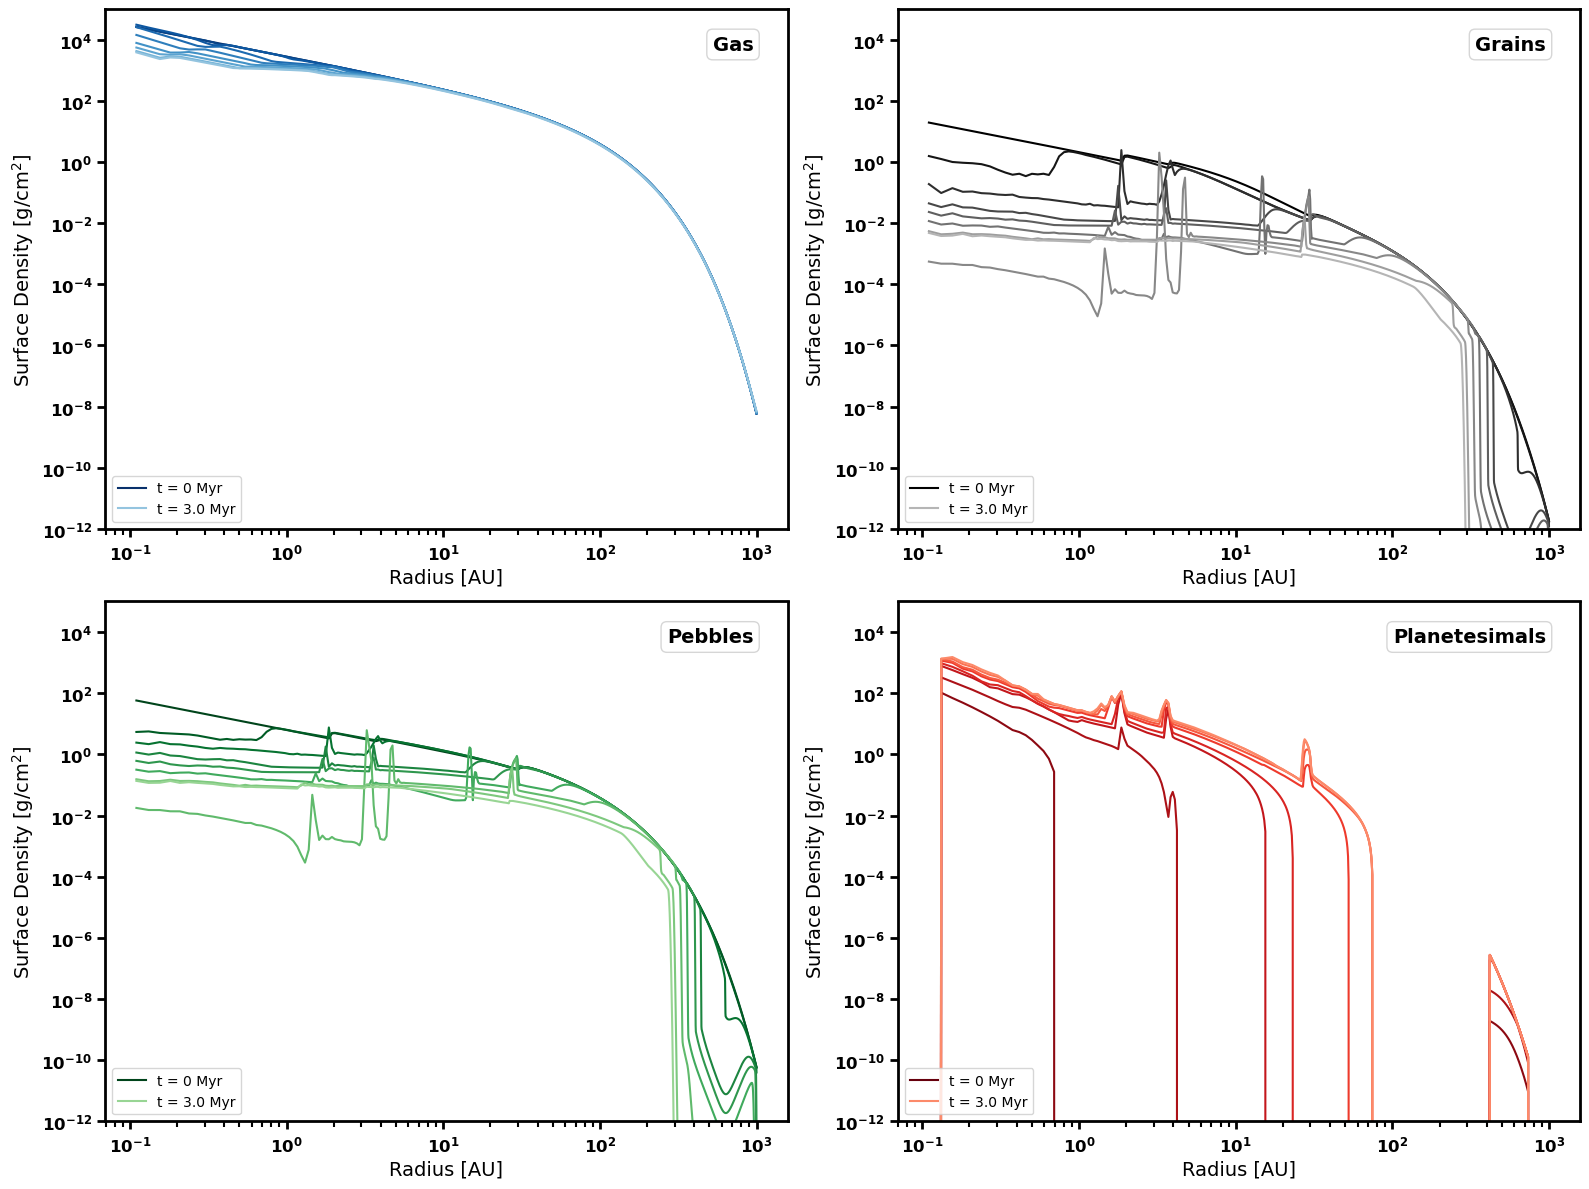

In [7]:
fig, ax = plt.subplots(2, 2, figsize = (8 * 2, 6 * 2))

for i in range(n_times):
    ## Label first and last timestep
    label = f't = {t_interval[i]} Myr' if i in (0, n_times - 1) else None

    ax[0, 0].plot(R, Sigma_G[i], color = color_blues[i], label = label)
    ax[0, 1].plot(R, Sigma_grains[i], color = color_greys[i], label = label)
    ax[1, 0].plot(R, Sigma_pebble[i], color = color_greens[i], label = label)

    if config["planetesimal"]["active"]:
        ax[1, 1].plot(R, Sigma_planetesimal[i], color = color_reds[i], label = label)

for i in range(2):
    for j in range(2):
        ax[i, j].set_xscale('log')
        ax[i, j].set_yscale('log')
        ax[i, j].set_xlabel('Radius [AU]')
        ax[i, j].set_ylabel(r'Surface Density [$\rm{g/cm^2}$]')
        ax[i, j].legend(loc = 'lower left', fontsize = 10)
        ax[i, j].set_ylim(1e-12, 1e5)

## Add panel labels

panel_labels = [['Gas', 'Grains'], ['Pebbles', 'Planetesimals']]

for i in range(2):
    for j in range(2):
        ax[i, j].text(0.95, 0.95, panel_labels[i][j], transform = ax[i, j].transAxes,
            ha = 'right', va = 'top', fontsize = 14, fontweight = 'bold',
            bbox = dict(boxstyle = 'round', facecolor = 'white', alpha = 0.8, edgecolor = '0.8'))

bold_ticks(*ax.flat)

plt.tight_layout()

if save_figures:
    figure_path = os.path.join(figure_dir, "surface_density_profiles.png")
    plt.savefig(figure_path)

plt.show()

## Helper Functions

In [8]:
## Pressure profile helper functions

def Omega_K(R):
    """Calculates the Keplerian angular velocity of the disk in rad/s."""
    M_star = 1.0 * Msun
    G = 6.67430e-8
    return np.sqrt(G * M_star / (R * AU) ** 3)

def rho_mid(R, Sigma_G, T):
    """Calculates the midplane gas density of the disk in g/cm^3."""
    return Sigma_G / (np.sqrt(2 * np.pi) * H(R, T) * AU)

def c_s(T):
    """Calculates the sound speed of the disk in cm/s."""
    mu = 2.33
    return np.sqrt(k_B * T / (mu * m_H))

def H(R, T):
    """Calculates the scale height of the disk in AU."""
    return c_s(T) / Omega_K(R) / AU

def P(R, Sigma_G, T):
    """Calculates the pressure of the disk in g/cm/s^2 assuming an ideal gas."""
    return rho_mid(R, Sigma_G, T) * c_s(T) ** 2

def dP_dR(R, Sigma_G, T):
    """Calculates the pressure gradient of the disk."""
    return np.gradient(P(R, Sigma_G, T), R * AU)

def dlnP_dlnR(R, Sigma_G, T):
    """Calculates dlnP/dlnR of the disk."""
    return (R * AU) / P(R, Sigma_G, T) * dP_dR(R, Sigma_G, T)

def eta(R, Sigma_G, T):
    """Calculates the eta parameter (Fortier et al 2012)."""
    return -1 * dP_dR(R, Sigma_G, T) / (2 * Omega_K(R) ** 2 * R * AU * rho_mid(R, Sigma_G, T))

## Temperature and Eta Profiles

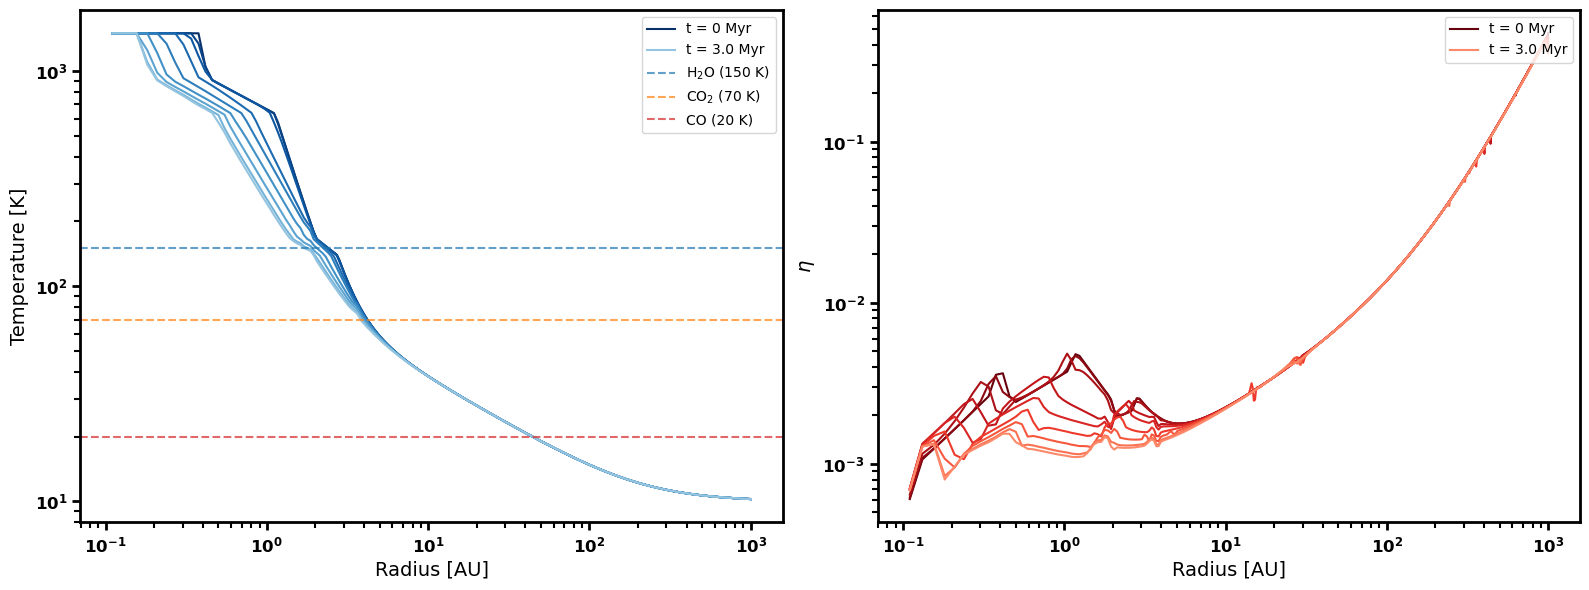

In [9]:
fig, ax = plt.subplots(1, 2, figsize = (8 * 2, 6))

for i in range(n_times):
    label = f't = {t_interval[i]} Myr' if i in (0, n_times - 1) else None

    ax[0].plot(R, T[i], color = color_blues[i], label = label)
    ax[1].plot(R, eta(R, Sigma_G[i], T[i]), color = color_reds[i], label = label)

ax[0].axhline(150, color = '#1f77b4', linestyle = '--', label = r'H$_2$O (150 K)', alpha = 0.7)
ax[0].axhline(70, color = '#ff7f0e', linestyle = '--', label = r'CO$_2$ (70 K)', alpha = 0.7)
ax[0].axhline(20, color = '#d62728', linestyle = '--', label = r'CO (20 K)', alpha = 0.7)

for i in range(2):
    ax[i].set_xscale('log')
    ax[i].set_yscale('log')
    ax[i].set_xlabel('Radius [AU]')
    ax[i].legend(loc = 'upper right', fontsize = 10)

ax[0].set_ylabel('Temperature [K]')
ax[1].set_ylabel(r'$\eta$')

bold_ticks(*ax)

plt.tight_layout()

if save_figures:
    figure_path = os.path.join(figure_dir, "temperature_eta_profiles.png")
    plt.savefig(figure_path)

plt.show()

## Eccentricity and Inclination Profiles

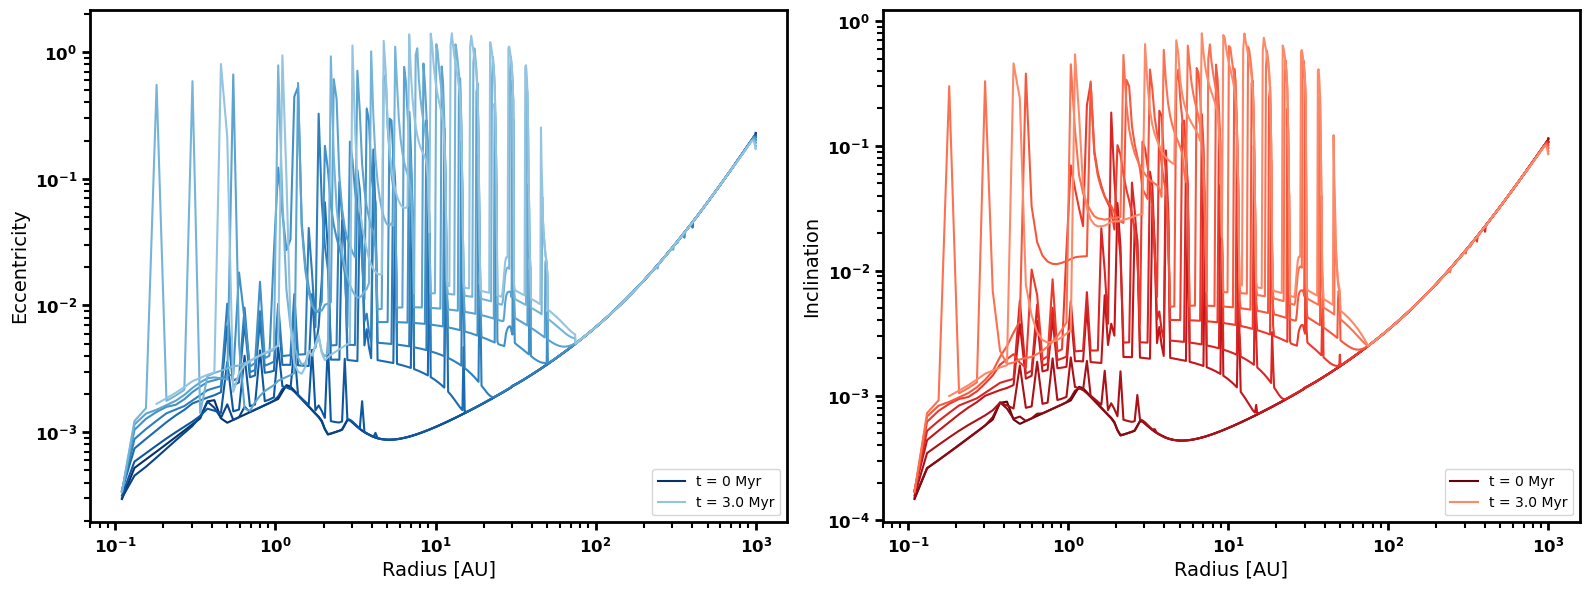

In [10]:
fig, ax = plt.subplots(1, 2, figsize = (8 * 2, 6))

for i in range(n_times):
    label = f't = {t_interval[i]} Myr' if i in (0, n_times - 1) else None

    if config["planetesimal"]["active"]:
        ax[0].plot(R, e_planetesimal[i], color = color_blues[i], label = label)
        ax[1].plot(R, i_planetesimal[i], color = color_reds[i], label = label)

for i in range(2):
    ax[i].set_xscale('log')
    ax[i].set_yscale('log')
    ax[i].set_xlabel('Radius [AU]')
    ax[i].legend(loc = 'lower right', fontsize = 10)

ax[0].set_ylabel('Eccentricity')
ax[1].set_ylabel('Inclination')

bold_ticks(*ax)

plt.tight_layout()

if save_figures:
    figure_path = os.path.join(figure_dir, "eccentricity_inclination_profiles.png")
    plt.savefig(figure_path)

plt.show()

## Eccentricity and Inclination Derivative Profiles

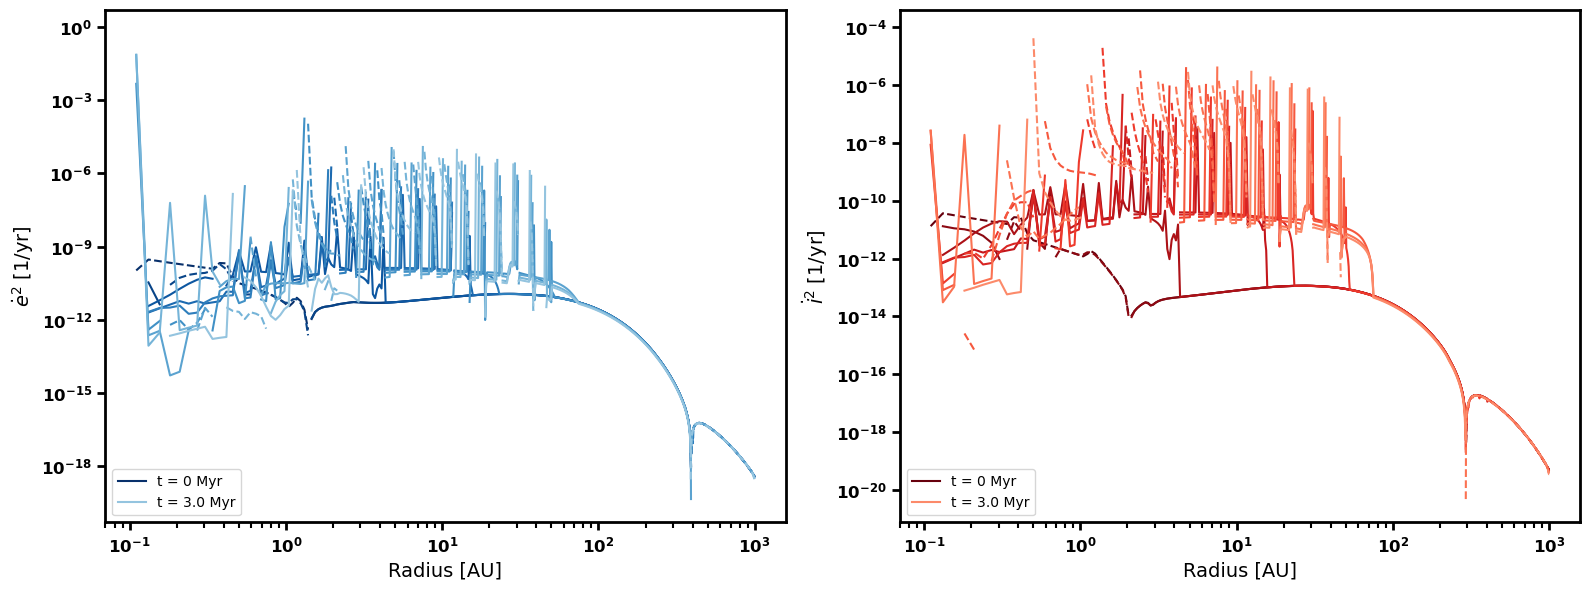

In [11]:
fig, ax = plt.subplots(1, 2, figsize = (8 * 2, 6))

for i in range(n_times):
    label = f't = {t_interval[i]} Myr' if i in (0, n_times - 1) else None

    if config["planetesimal"]["drag"] or config["planetesimal"]["VS_embryo"] or config["planetesimal"]["VS_pltsml"] or config["planetesimal"]["DF"]:
        ax[0].plot(R, np.where(de2_dt[i] > 0, de2_dt[i], np.nan), color = color_blues[i], linestyle = '-', label = label)
        ax[0].plot(R, np.where(de2_dt[i] < 0, -1 * de2_dt[i], np.nan), color = color_blues[i], linestyle = '--')

        ax[1].plot(R, np.where(di2_dt[i] > 0, di2_dt[i], np.nan), color = color_reds[i], linestyle = '-', label = label)
        ax[1].plot(R, np.where(di2_dt[i] < 0, -1 * di2_dt[i], np.nan), color = color_reds[i], linestyle = '--')

for i in range(2):
    ax[i].set_xscale('log')
    ax[i].set_yscale('log')
    ax[i].set_xlabel('Radius [AU]')
    ax[i].set_ylabel('[1/yr]')
    ax[i].legend(loc = 'lower left', fontsize = 10)

ax[0].set_ylabel(r'$\dot e^2$ [1/yr]')
ax[1].set_ylabel(r'$\dot i^2$ [1/yr]')

bold_ticks(*ax)

plt.tight_layout()

if save_figures:
    figure_path = os.path.join(figure_dir, "de2dt_di2dt_profiles.png")
    plt.savefig(figure_path)

plt.show()

## Eccentricity and Inclination Derivative Terms

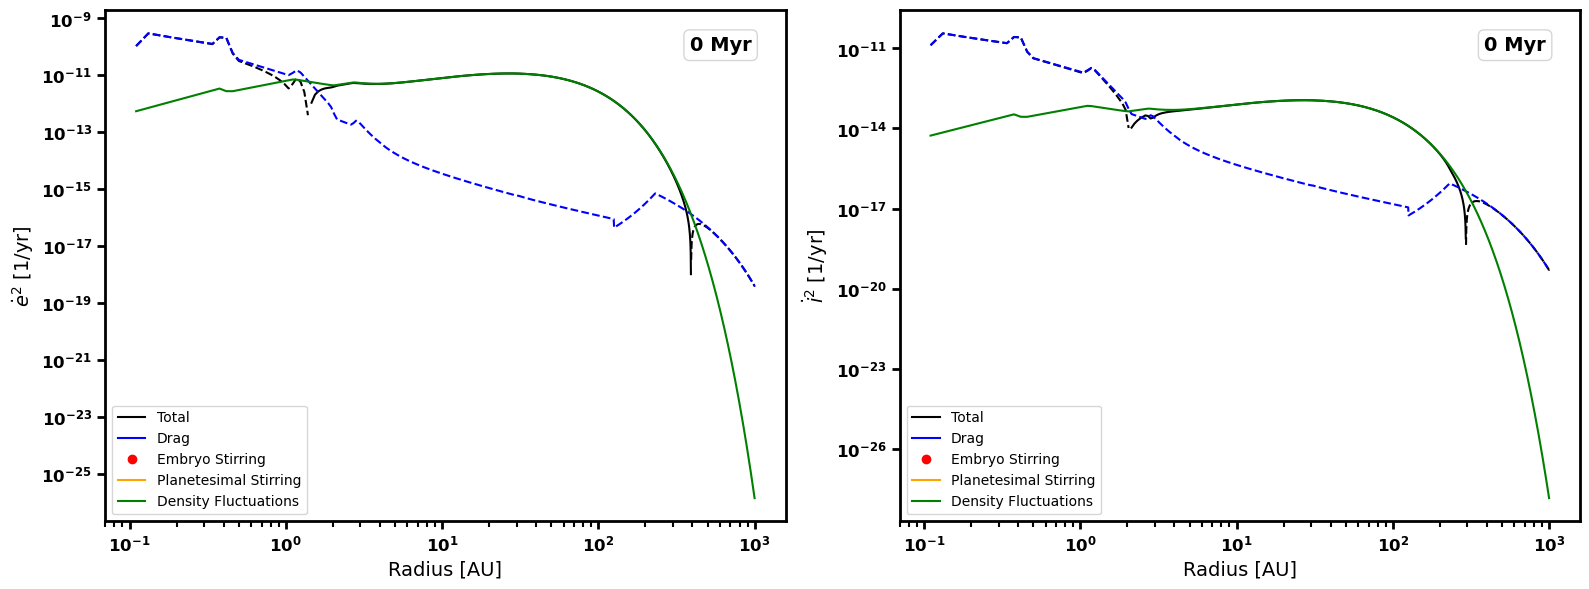

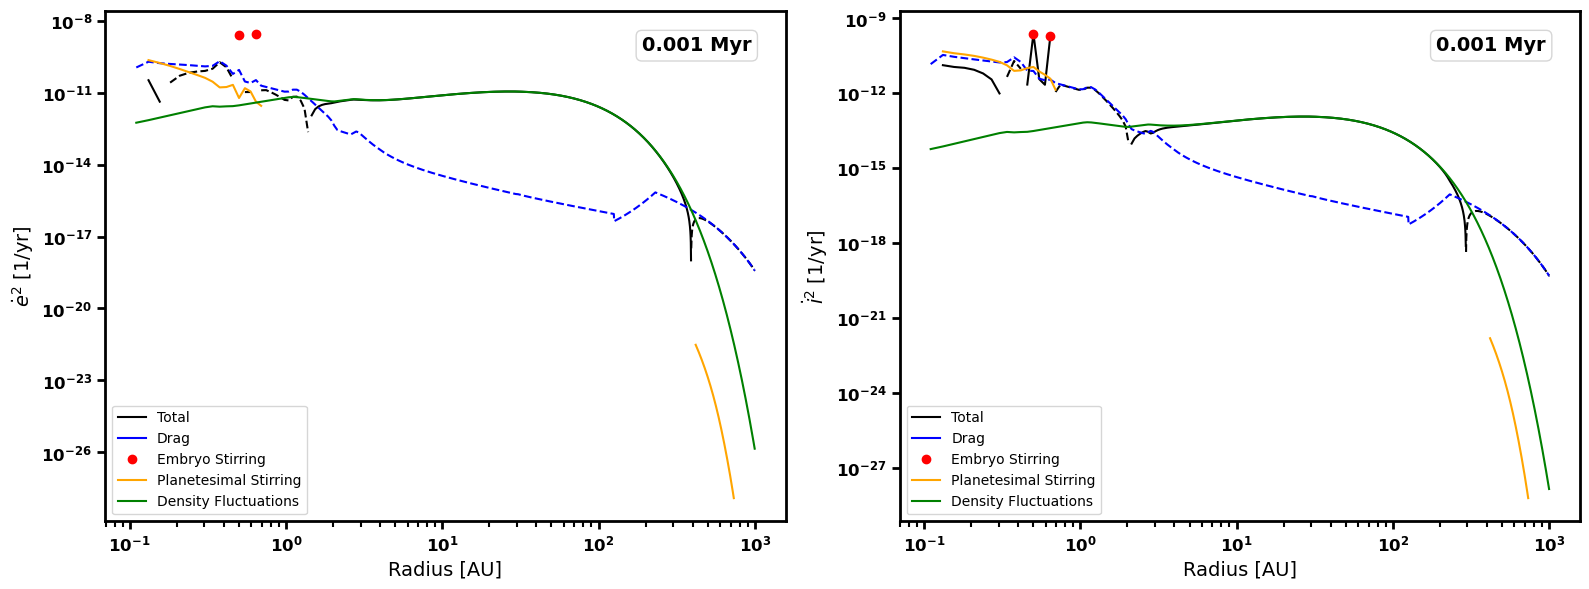

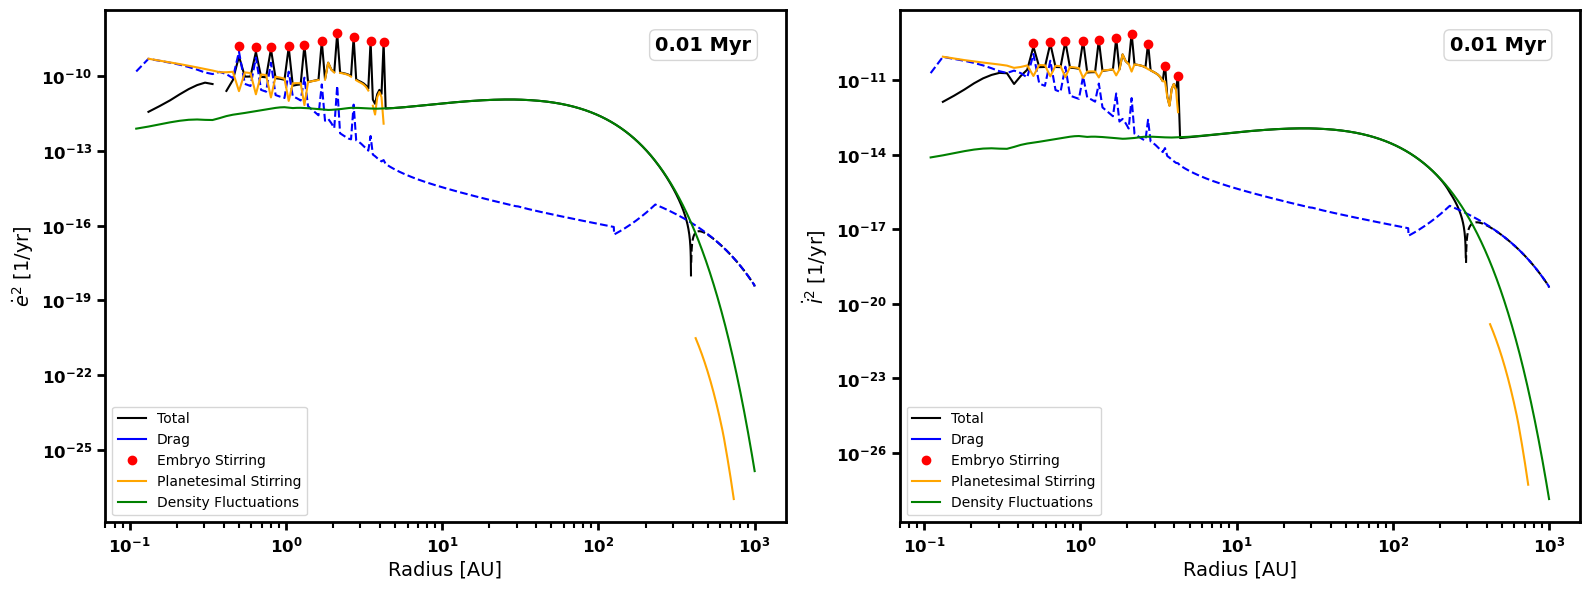

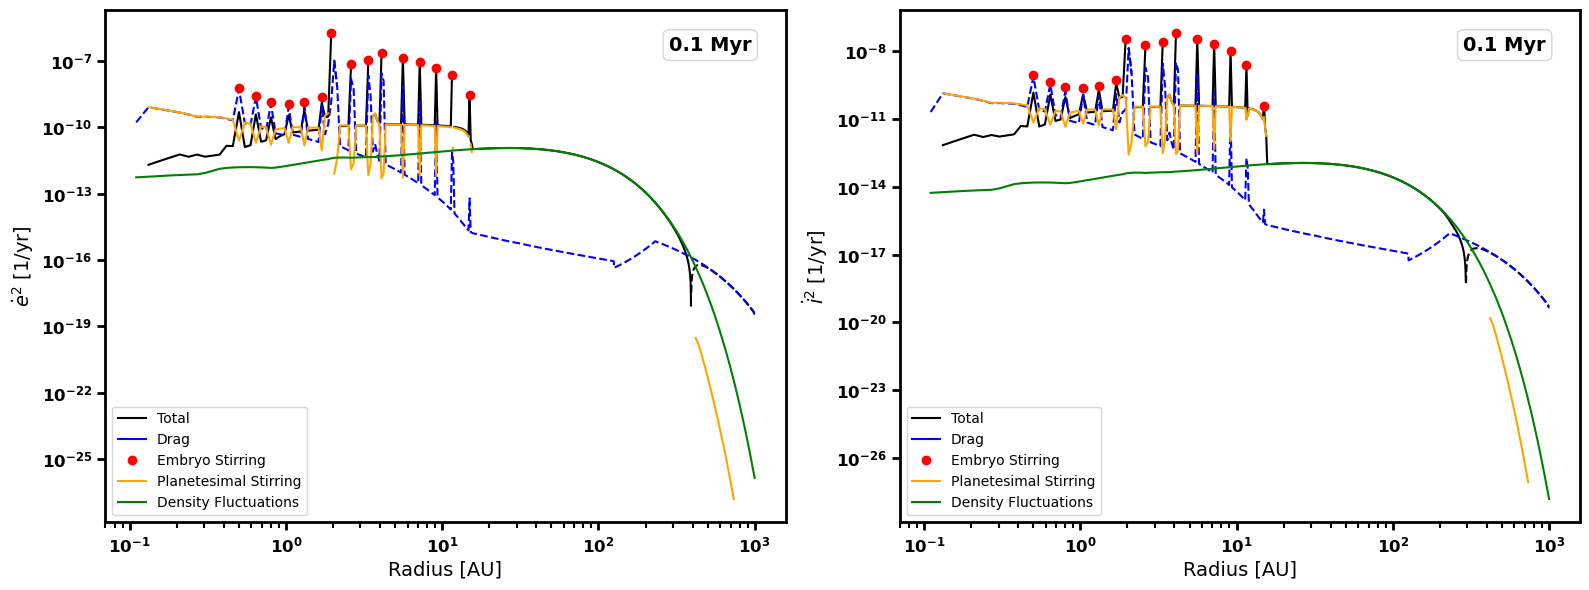

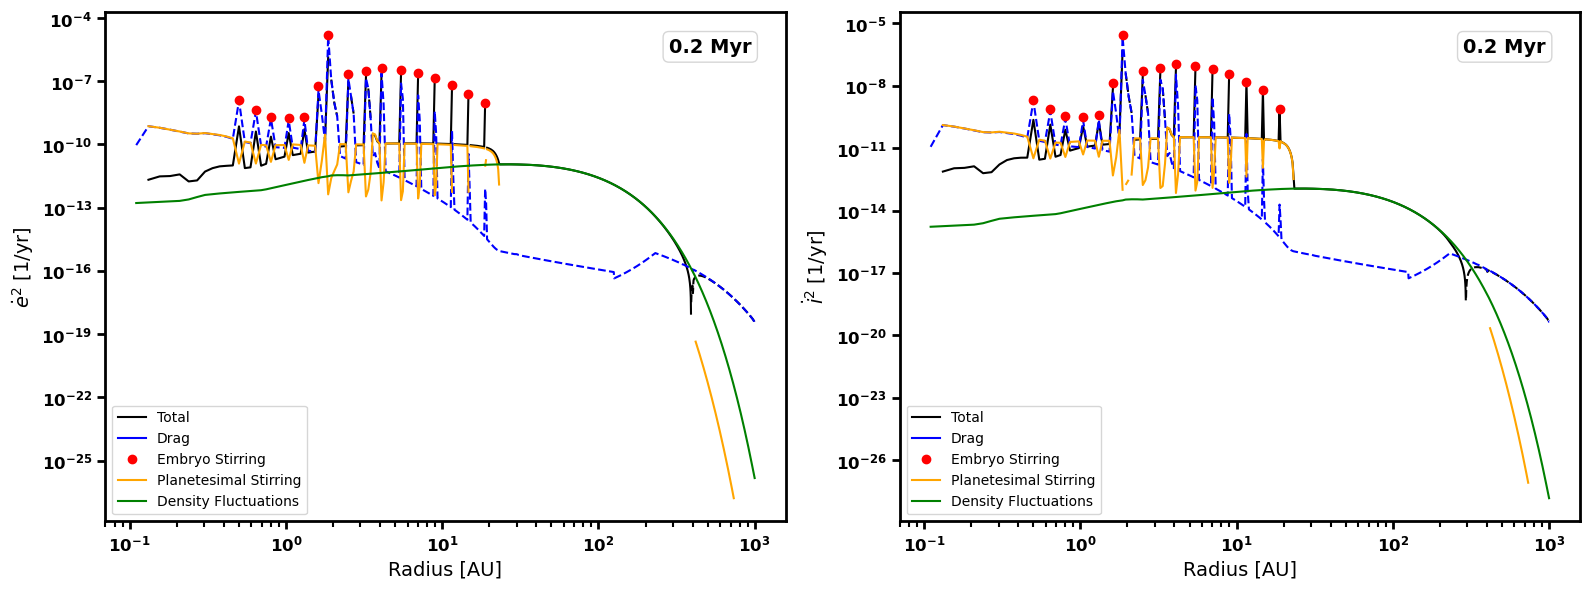

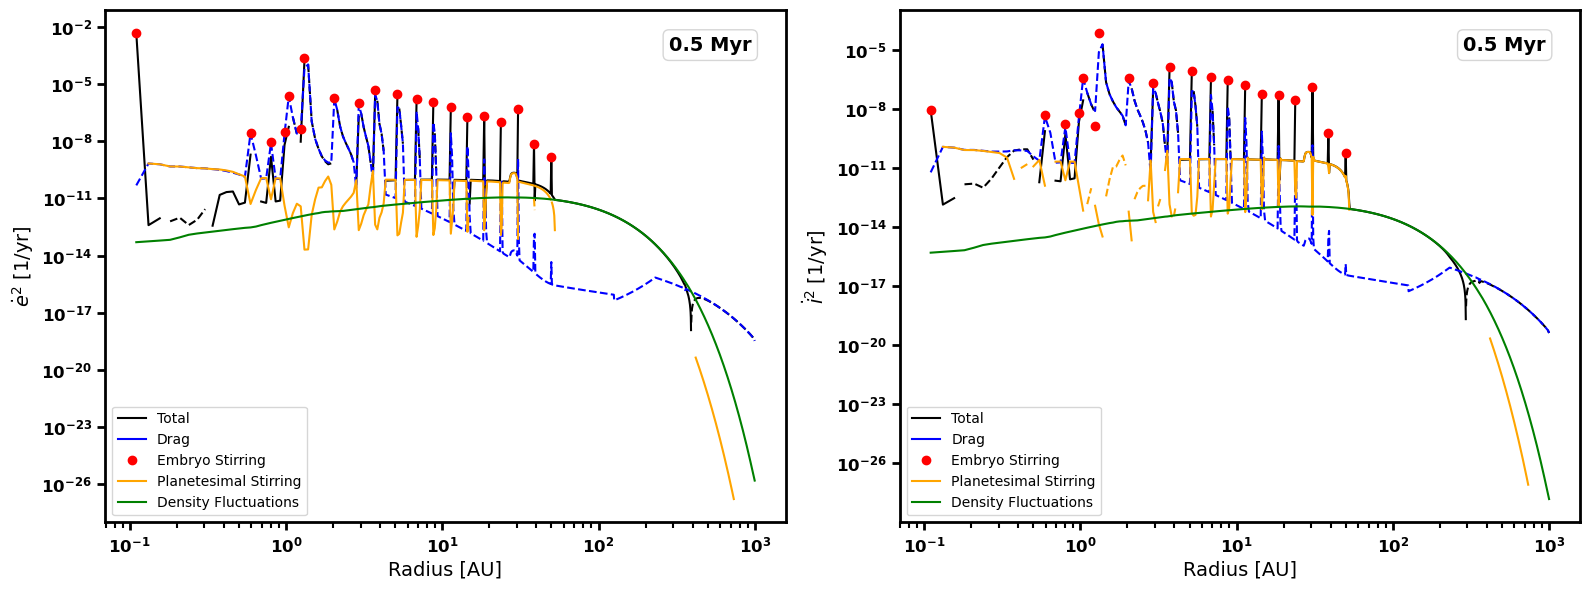

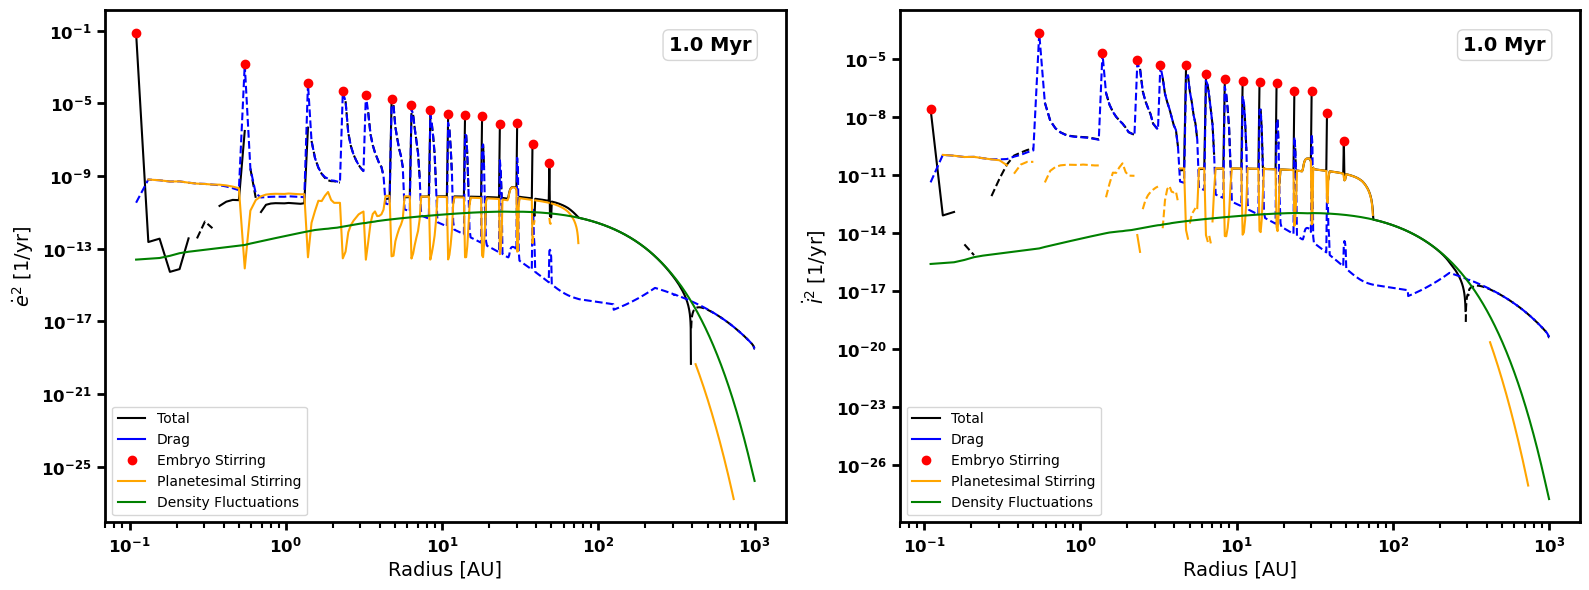

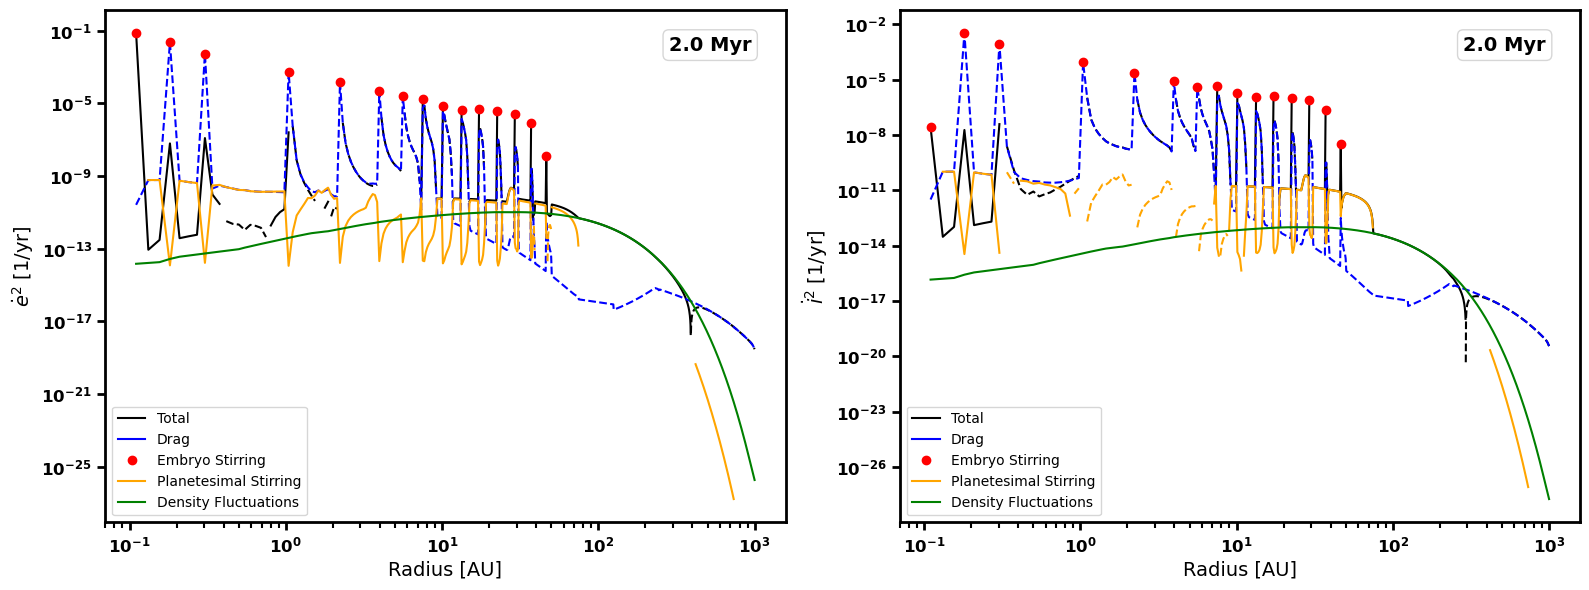

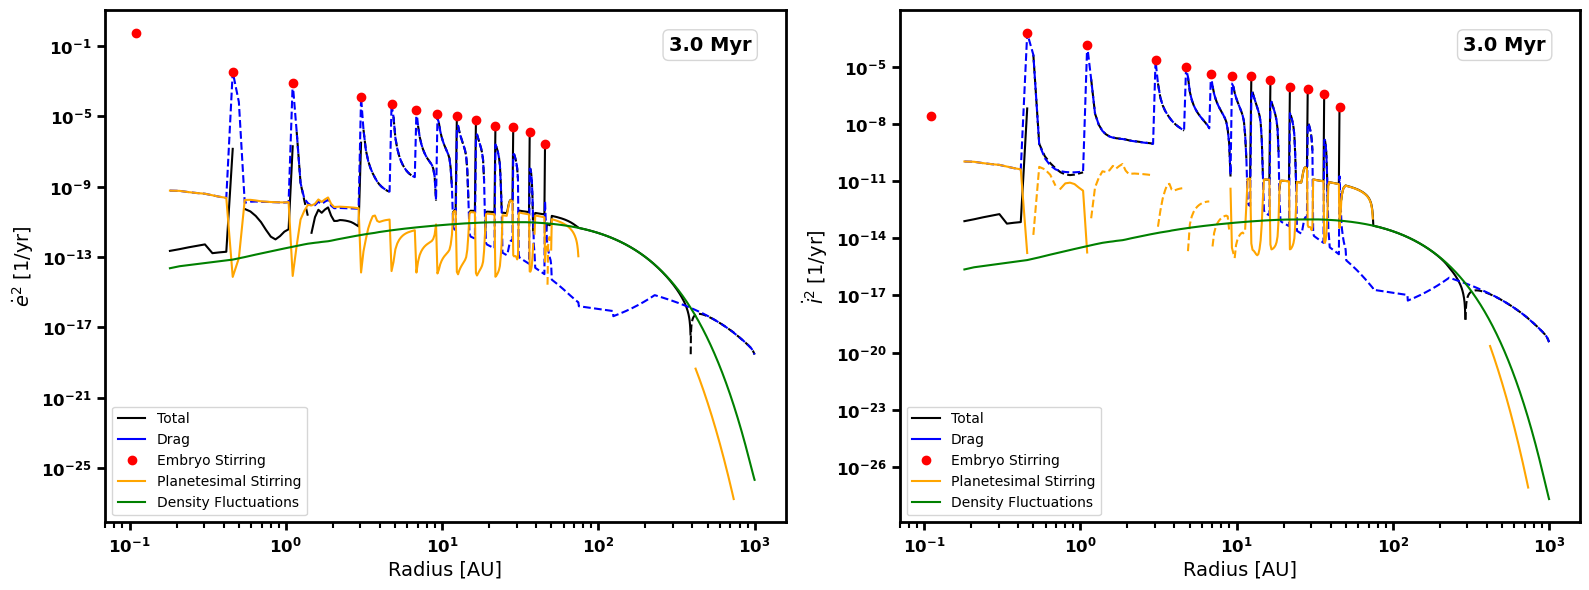

In [12]:
for i in range(n_times):
    fig, ax = plt.subplots(1, 2, figsize = (8 * 2, 6))

    ## Eccentricity derivatives
    if config["planetesimal"]["drag"] or config["planetesimal"]["VS_embryo"] or config["planetesimal"]["VS_pltsml"] or config["planetesimal"]["DF"]:
        ax[0].plot(R, np.where(de2_dt[i] > 0, de2_dt[i], np.nan), color = 'black', linestyle = '-', label = 'Total')
        ax[0].plot(R, np.where(de2_dt[i] < 0, -1 * de2_dt[i], np.nan), color = 'black', linestyle = '--')
    
    ## Drag
    if config["planetesimal"]["drag"]:
        ax[0].plot(R, np.where(de2_dt_drag[i] > 0, de2_dt_drag[i], np.nan), color = 'blue', linestyle = '-', label = 'Drag')
        ax[0].plot(R, np.where(de2_dt_drag[i] < 0, -1 * de2_dt_drag[i], np.nan), color = 'blue', linestyle = '--')

    ## Embryo stirring
    if config["planetesimal"]["VS_embryo"]:
        ax[0].plot(R, np.where(de2_dt_VS_embryo[i] > 0, de2_dt_VS_embryo[i], np.nan), color = 'red', linestyle = 'None', marker = 'o', label = 'Embryo Stirring')
        ax[0].plot(R, np.where(de2_dt_VS_embryo[i] < 0, -1 * de2_dt_VS_embryo[i], np.nan), color = 'red', linestyle = 'None', marker = 's')

    ## Planetesimal stirring
    if config["planetesimal"]["VS_pltsml"]:
        ax[0].plot(R, np.where(de2_dt_VS_pltsml[i] > 0, de2_dt_VS_pltsml[i], np.nan), color = 'orange', linestyle = '-', label = 'Planetesimal Stirring')
        ax[0].plot(R, np.where(de2_dt_VS_pltsml[i] < 0, -1 * de2_dt_VS_pltsml[i], np.nan), color = 'orange', linestyle = '--')

    ## Density fluctuations
    if config["planetesimal"]["DF"]:
        ax[0].plot(R, np.where(de2_dt_DF[i] > 0, de2_dt_DF[i], np.nan), color = 'green', linestyle = '-', label = 'Density Fluctuations')
        ax[0].plot(R, np.where(de2_dt_DF[i] < 0, -1 * de2_dt_DF[i], np.nan), color = 'green', linestyle = '--')

    ax[0].set_xscale('log')
    ax[0].set_yscale('log')
    ax[0].set_xlabel('Radius [AU]')
    ax[0].set_ylabel(r'$\dot e^2$ [1/yr]')
    ax[0].legend(loc = 'lower left', fontsize = 10)

    ax[0].text(0.95, 0.95, f'{t_interval[i]} Myr', transform = ax[0].transAxes,
        ha = 'right', va = 'top', fontsize = 14, fontweight = 'bold',
        bbox = dict(boxstyle = 'round', facecolor = 'white', alpha = 0.8, edgecolor = '0.8'))

    ## Inclination derivatives
    if config["planetesimal"]["drag"] or config["planetesimal"]["VS_embryo"] or config["planetesimal"]["VS_pltsml"] or config["planetesimal"]["DF"]:
        ax[1].plot(R, np.where(di2_dt[i] > 0, di2_dt[i], np.nan), color = 'black', linestyle = '-', label = 'Total')
        ax[1].plot(R, np.where(di2_dt[i] < 0, -1 * di2_dt[i], np.nan), color = 'black', linestyle = '--')

    ## Drag
    if config["planetesimal"]["drag"]:
        ax[1].plot(R, np.where(di2_dt_drag[i] > 0, di2_dt_drag[i], np.nan), color = 'blue', linestyle = '-', label = 'Drag')
        ax[1].plot(R, np.where(di2_dt_drag[i] < 0, -1 * di2_dt_drag[i], np.nan), color = 'blue', linestyle = '--')

    ## Embryo stirring
    if config["planetesimal"]["VS_embryo"]:
        ax[1].plot(R, np.where(di2_dt_VS_embryo[i] > 0, di2_dt_VS_embryo[i], np.nan), color = 'red', linestyle = 'None', marker = 'o', label = 'Embryo Stirring')
        ax[1].plot(R, np.where(di2_dt_VS_embryo[i] < 0, -1 * di2_dt_VS_embryo[i], np.nan), color = 'red', linestyle = 'None', marker = 's')

    ## Planetesimal stirring
    if config["planetesimal"]["VS_pltsml"]:
        ax[1].plot(R, np.where(di2_dt_VS_pltsml[i] > 0, di2_dt_VS_pltsml[i], np.nan), color = 'orange', linestyle = '-', label = 'Planetesimal Stirring')
        ax[1].plot(R, np.where(di2_dt_VS_pltsml[i] < 0, -1 * di2_dt_VS_pltsml[i], np.nan), color = 'orange', linestyle = '--')

    ## Density fluctuations
    if config["planetesimal"]["DF"]:
        ax[1].plot(R, np.where(di2_dt_DF[i] > 0, di2_dt_DF[i], np.nan), color = 'green', linestyle = '-', label = 'Density Fluctuations')
        ax[1].plot(R, np.where(di2_dt_DF[i] < 0, -1 * di2_dt_DF[i], np.nan), color = 'green', linestyle = '--')

    ax[1].set_xscale('log')
    ax[1].set_yscale('log')
    ax[1].set_xlabel('Radius [AU]')
    ax[1].set_ylabel(r'$\dot i^2$ [1/yr]')
    ax[1].legend(loc = 'lower left', fontsize = 10)

    ax[1].text(0.95, 0.95, f'{t_interval[i]} Myr', transform = ax[1].transAxes,
        ha = 'right', va = 'top', fontsize = 14, fontweight = 'bold',
        bbox = dict(boxstyle = 'round', facecolor = 'white', alpha = 0.8, edgecolor = '0.8'))

    bold_ticks(*ax)

    plt.tight_layout()

    if save_figures:
        os.makedirs(f'{figure_dir}/de2dt_di2dt_profiles/', exist_ok = True)
        figure_path = os.path.join(f'{figure_dir}/de2dt_di2dt_profiles/', f"de2dt_di2dt_profiles_{t_interval[i]}Myr.png")
        plt.savefig(figure_path)

    plt.show()

## Helper Functions

In [13]:
## Method to cumulatively integrate an accretion rate over time

def cumulative_mass_accreted(t, Mdot):
    """
    Cumulatively integrate the accretion rate over time to give accreted mass at each timestep.

    Parameters:
        t: Array of times, shape (n_times).
        Mdot: Array of accretion rates, shape (n_times) or (n_planets, n_times).

    Returns:
        Array of the same shape as Mdot giving the cumulative mass accreted up to each timestep.
    """

    Mdot = np.nan_to_num(Mdot, nan = 0.0)

    M = [0.0]

    for k in range(len(t) - 1):
        dt = t[k + 1] - t[k]
        M.append(M[-1] + Mdot[k] * dt)

    return np.array(M)

## Planet Profiles

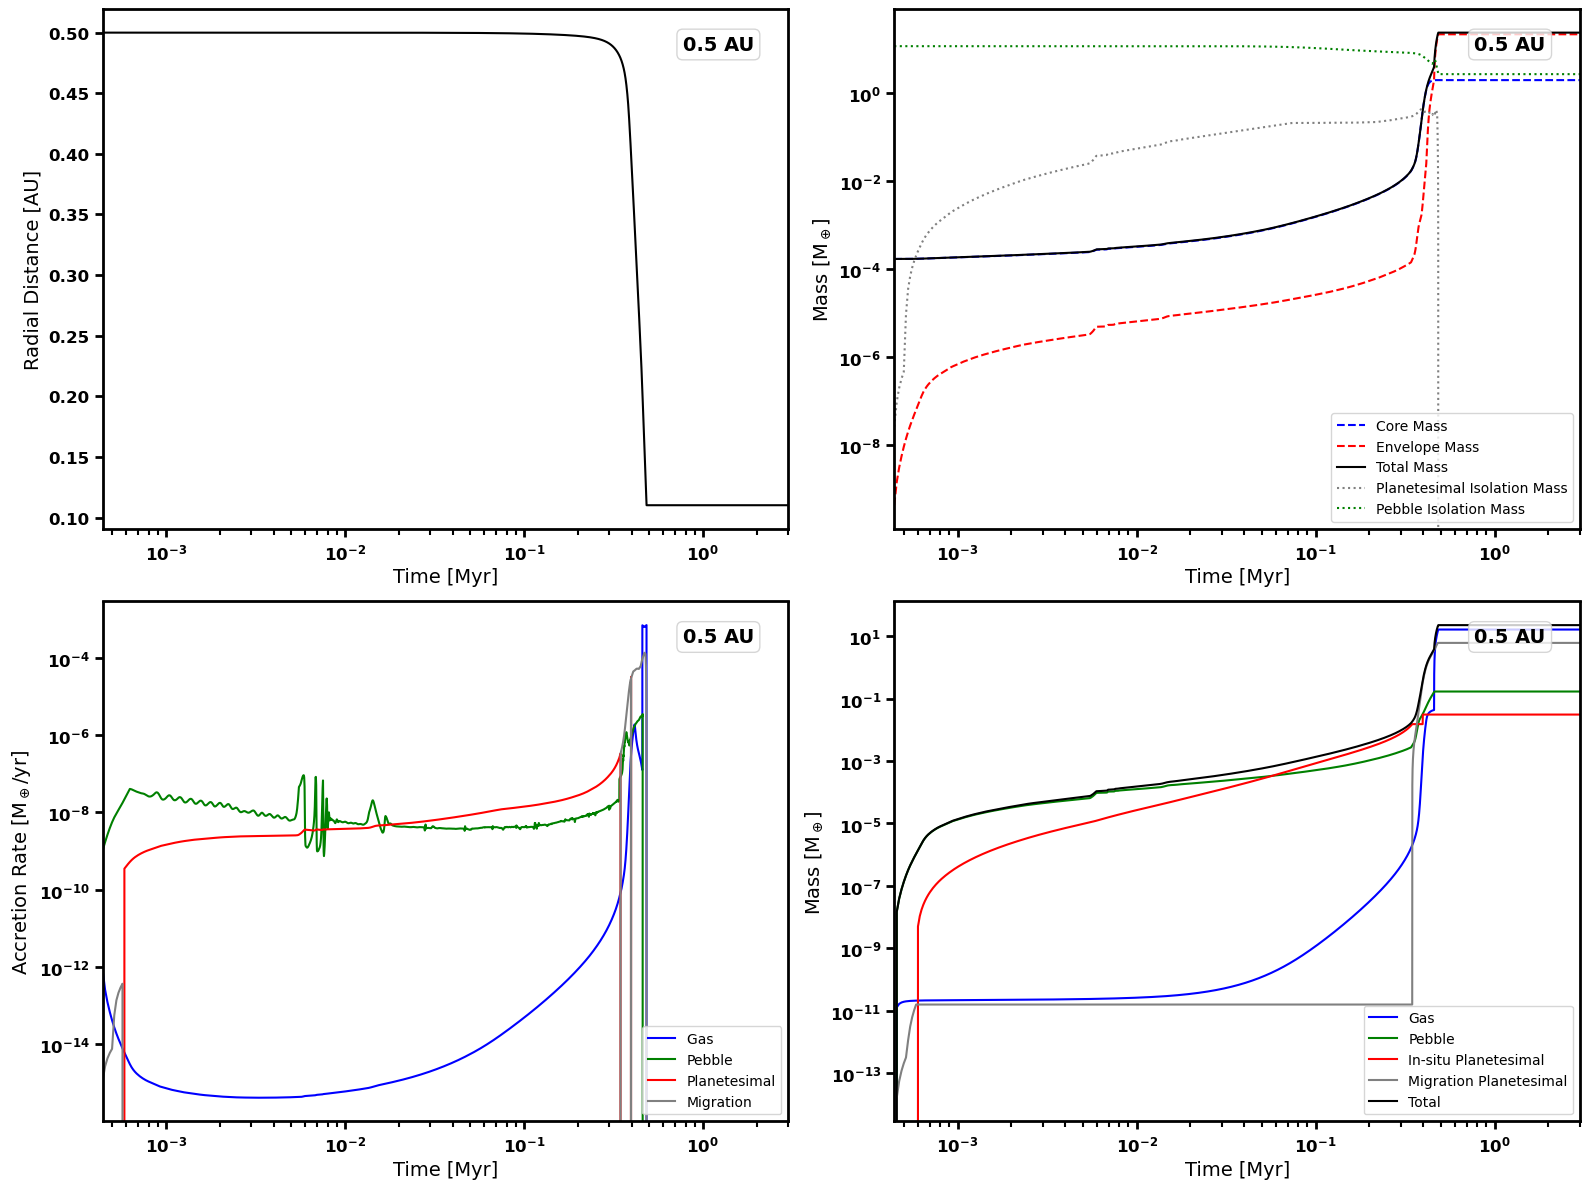

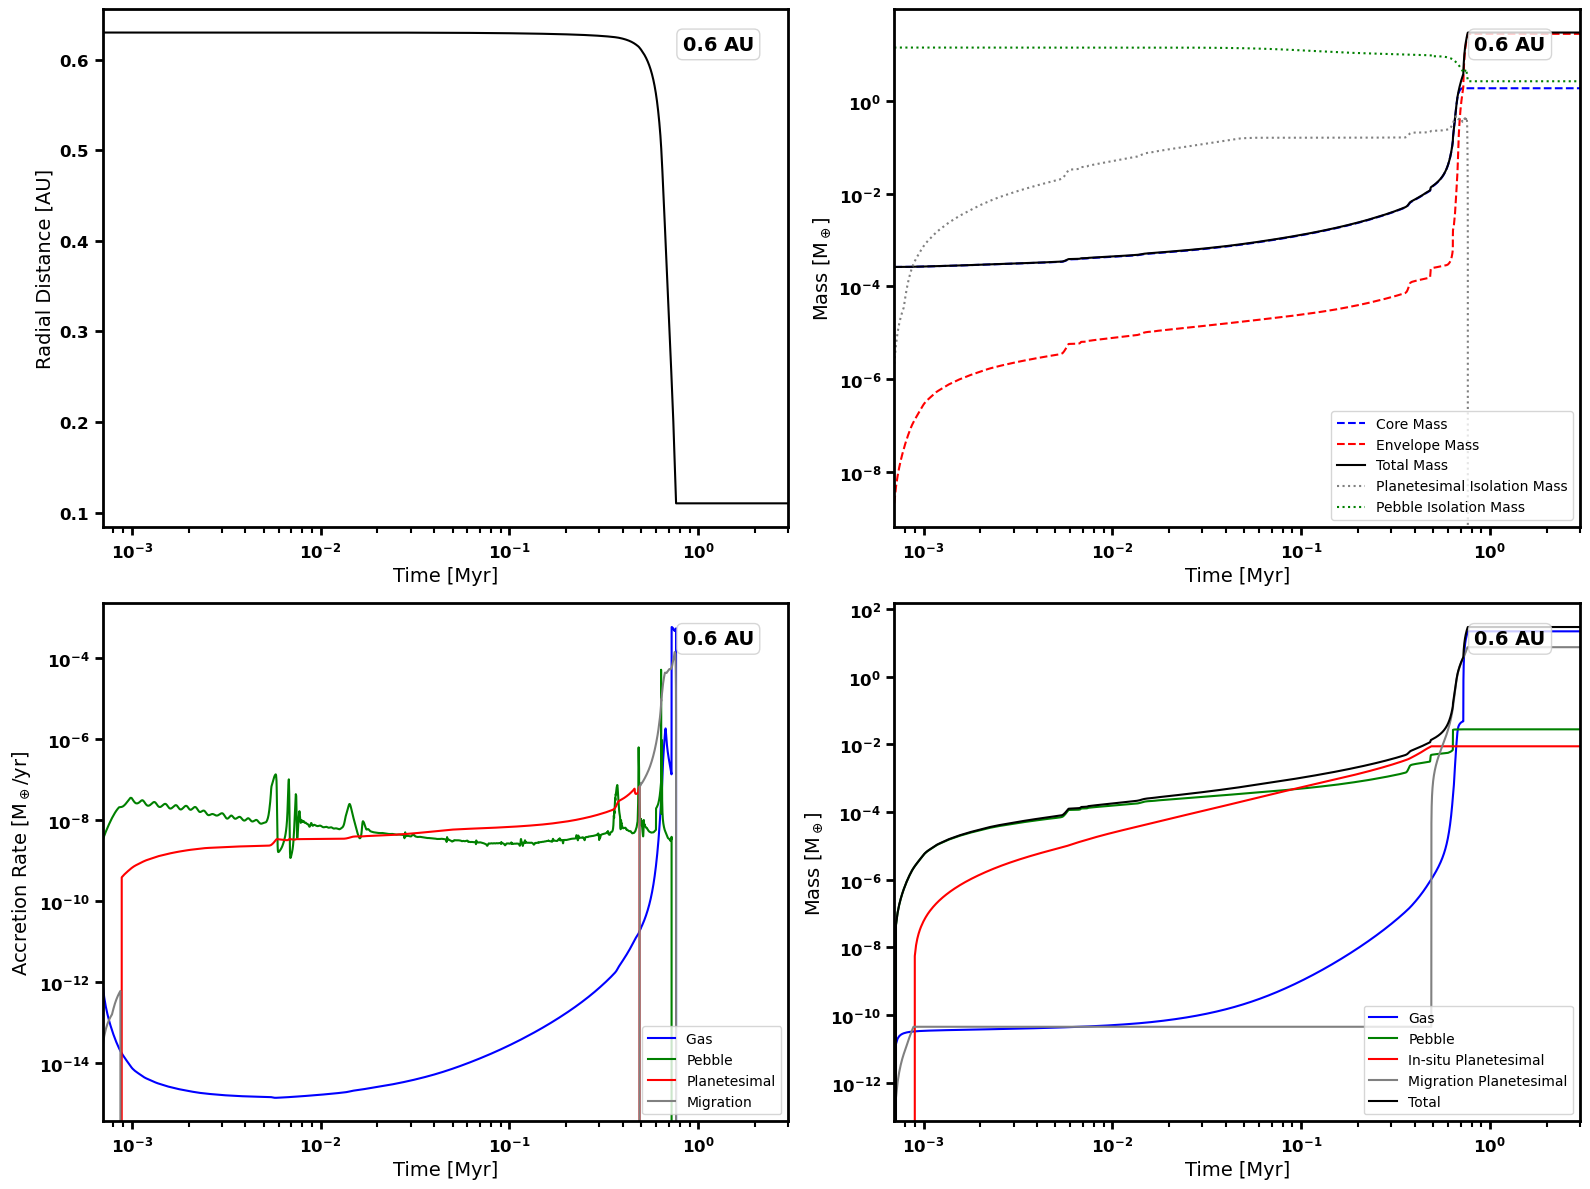

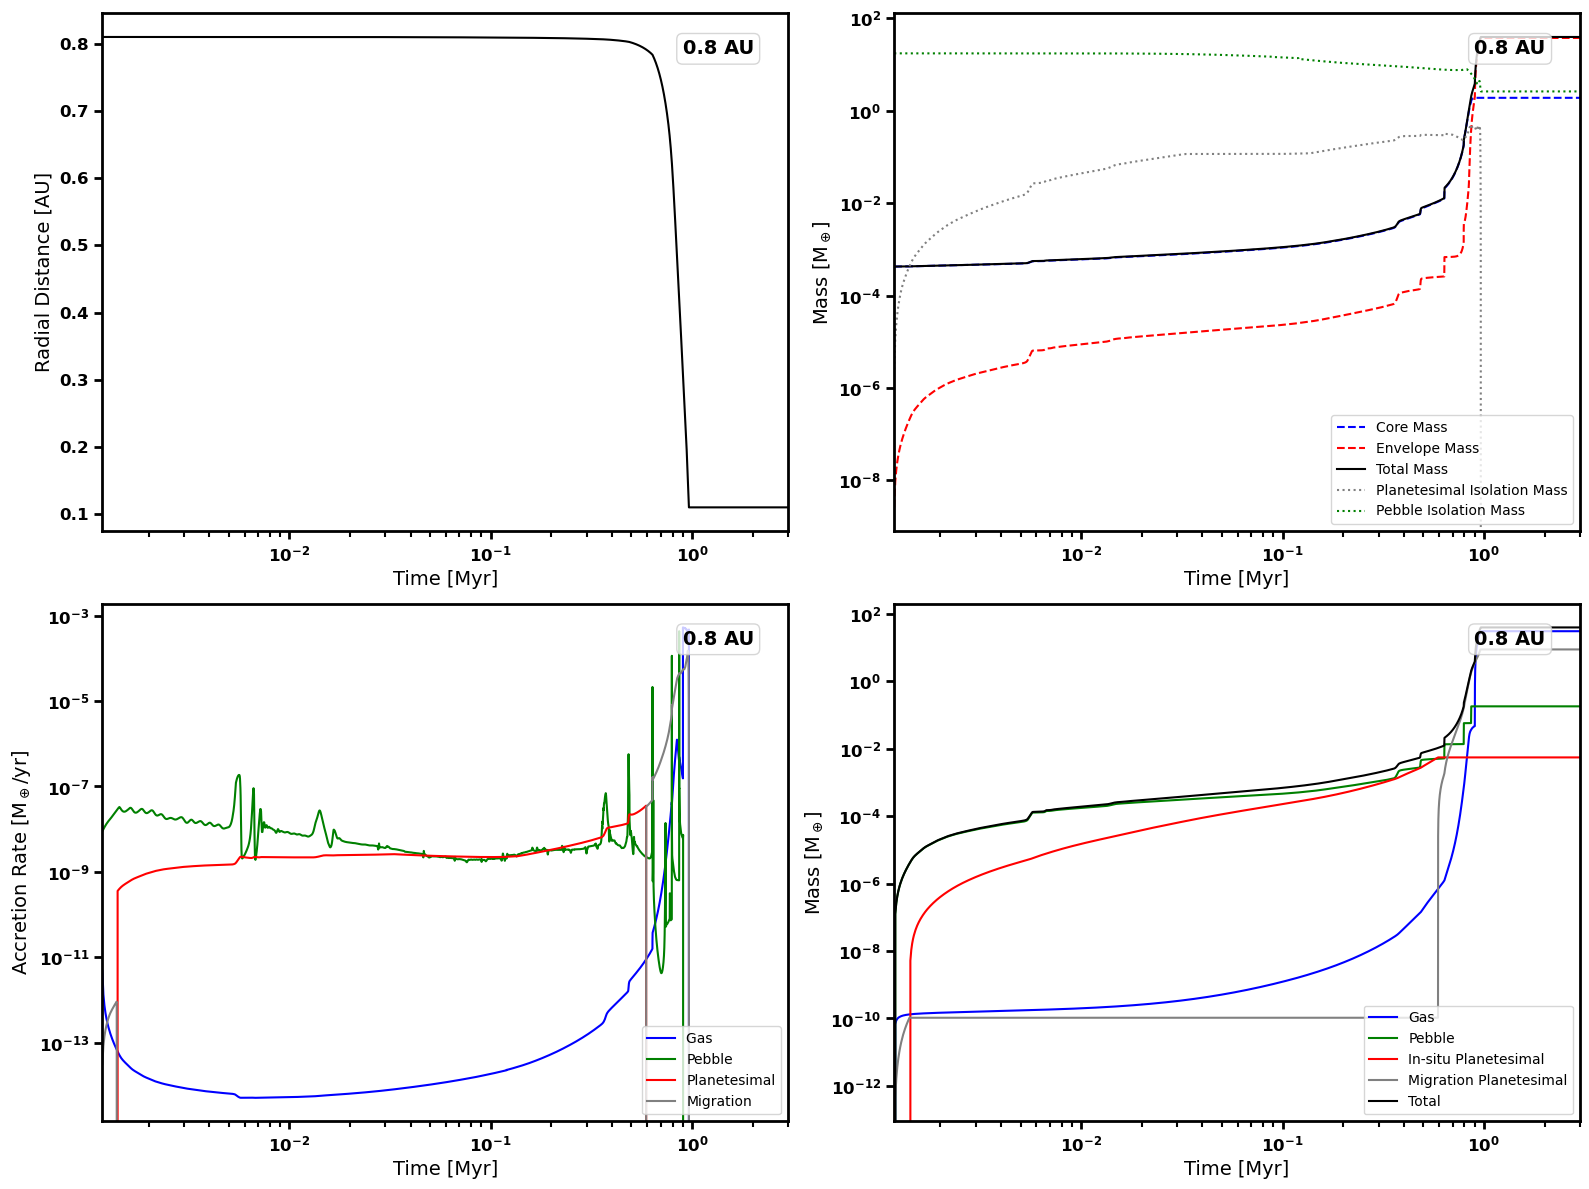

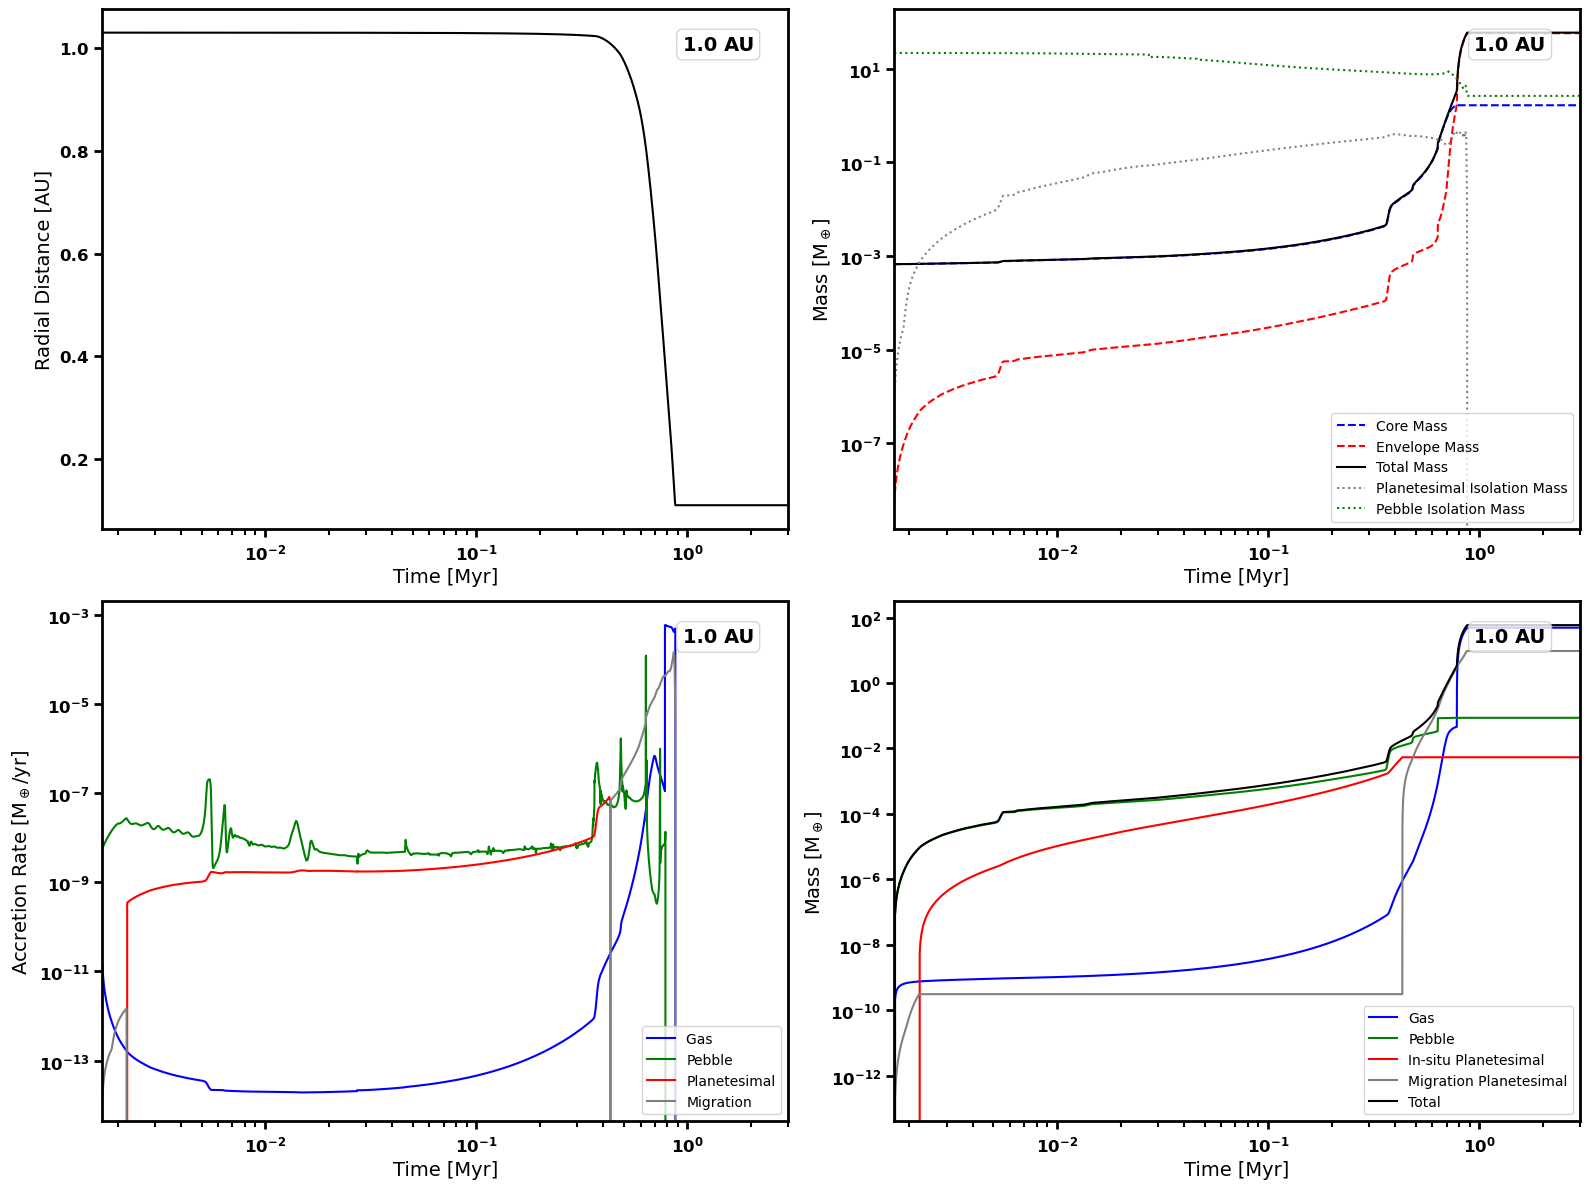

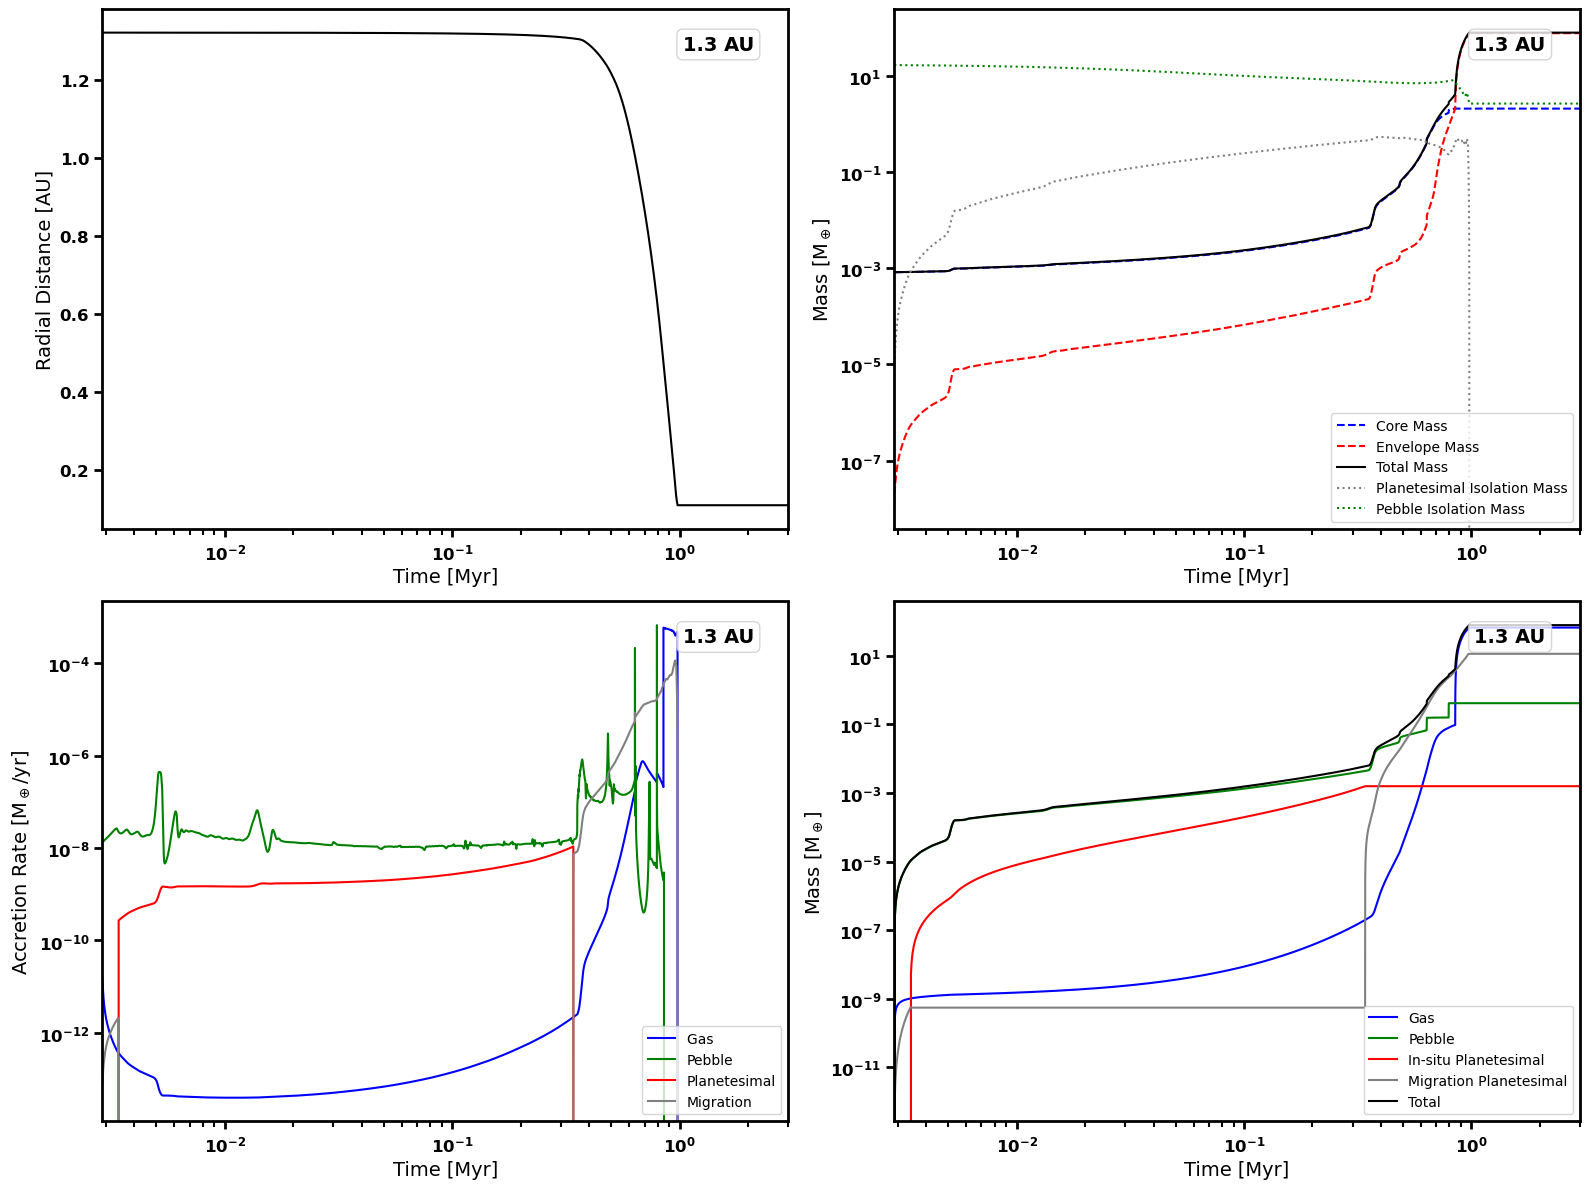

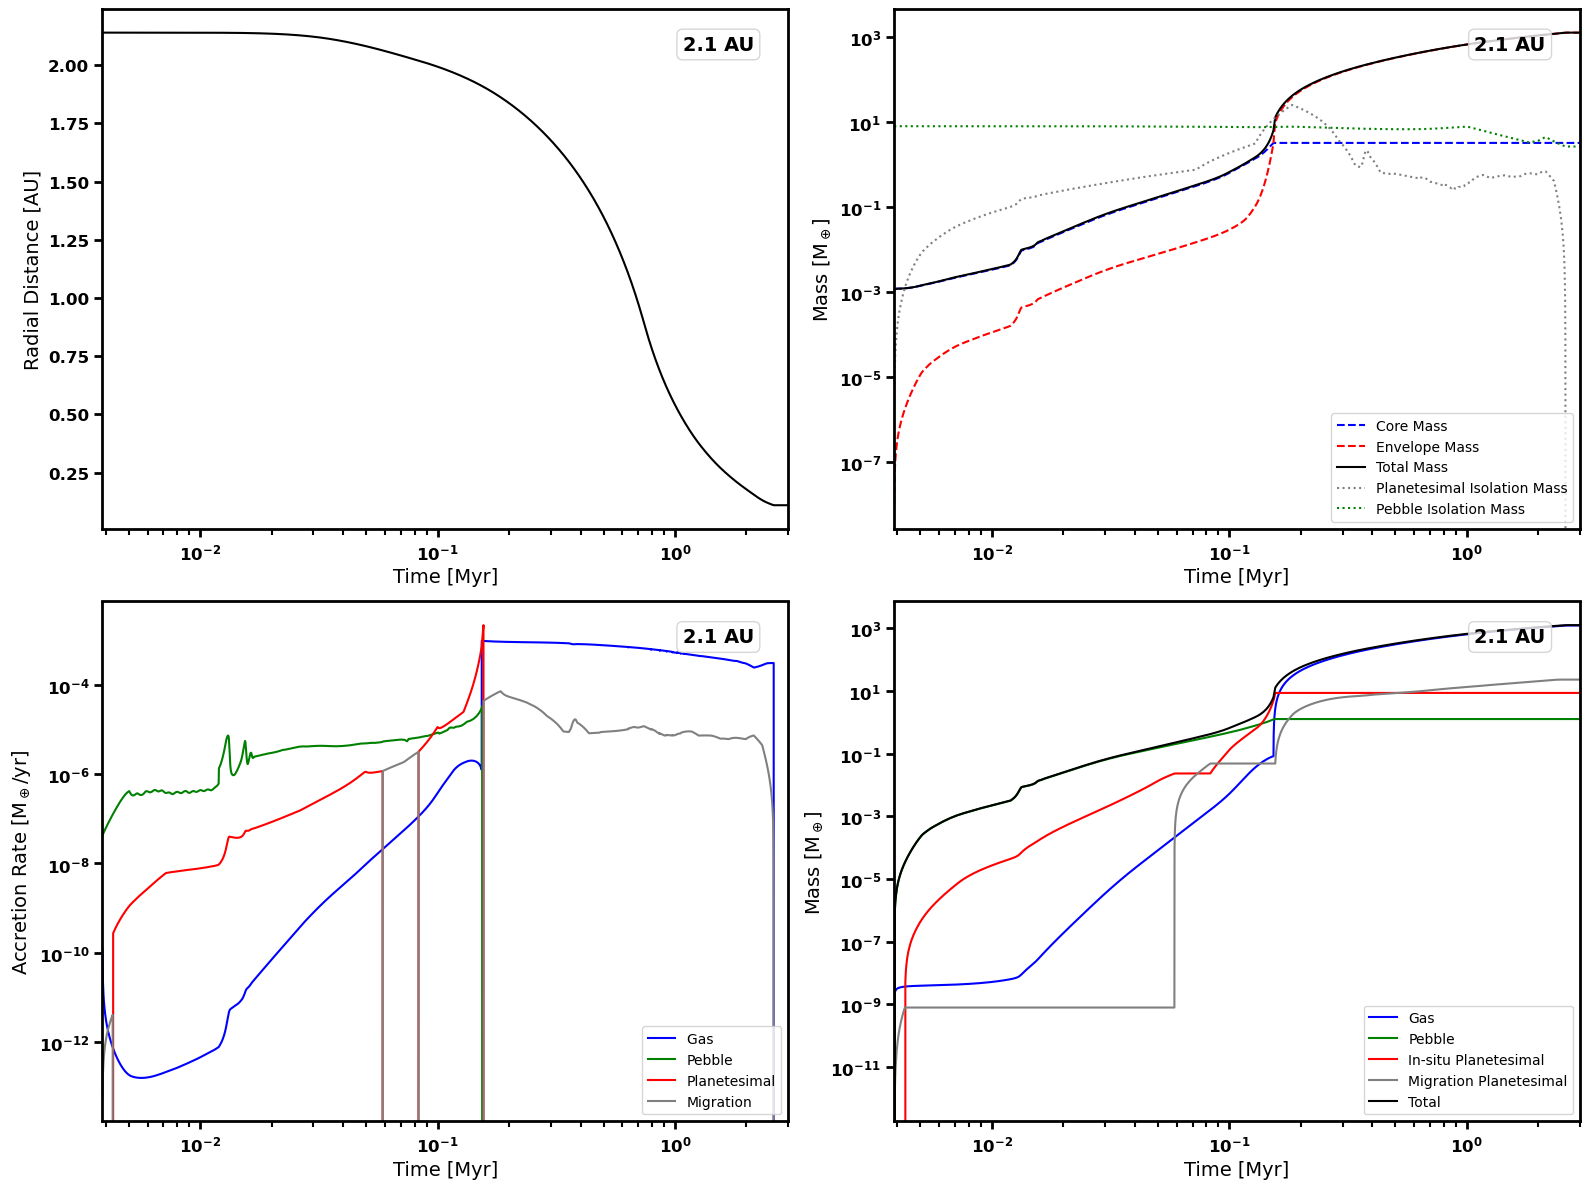

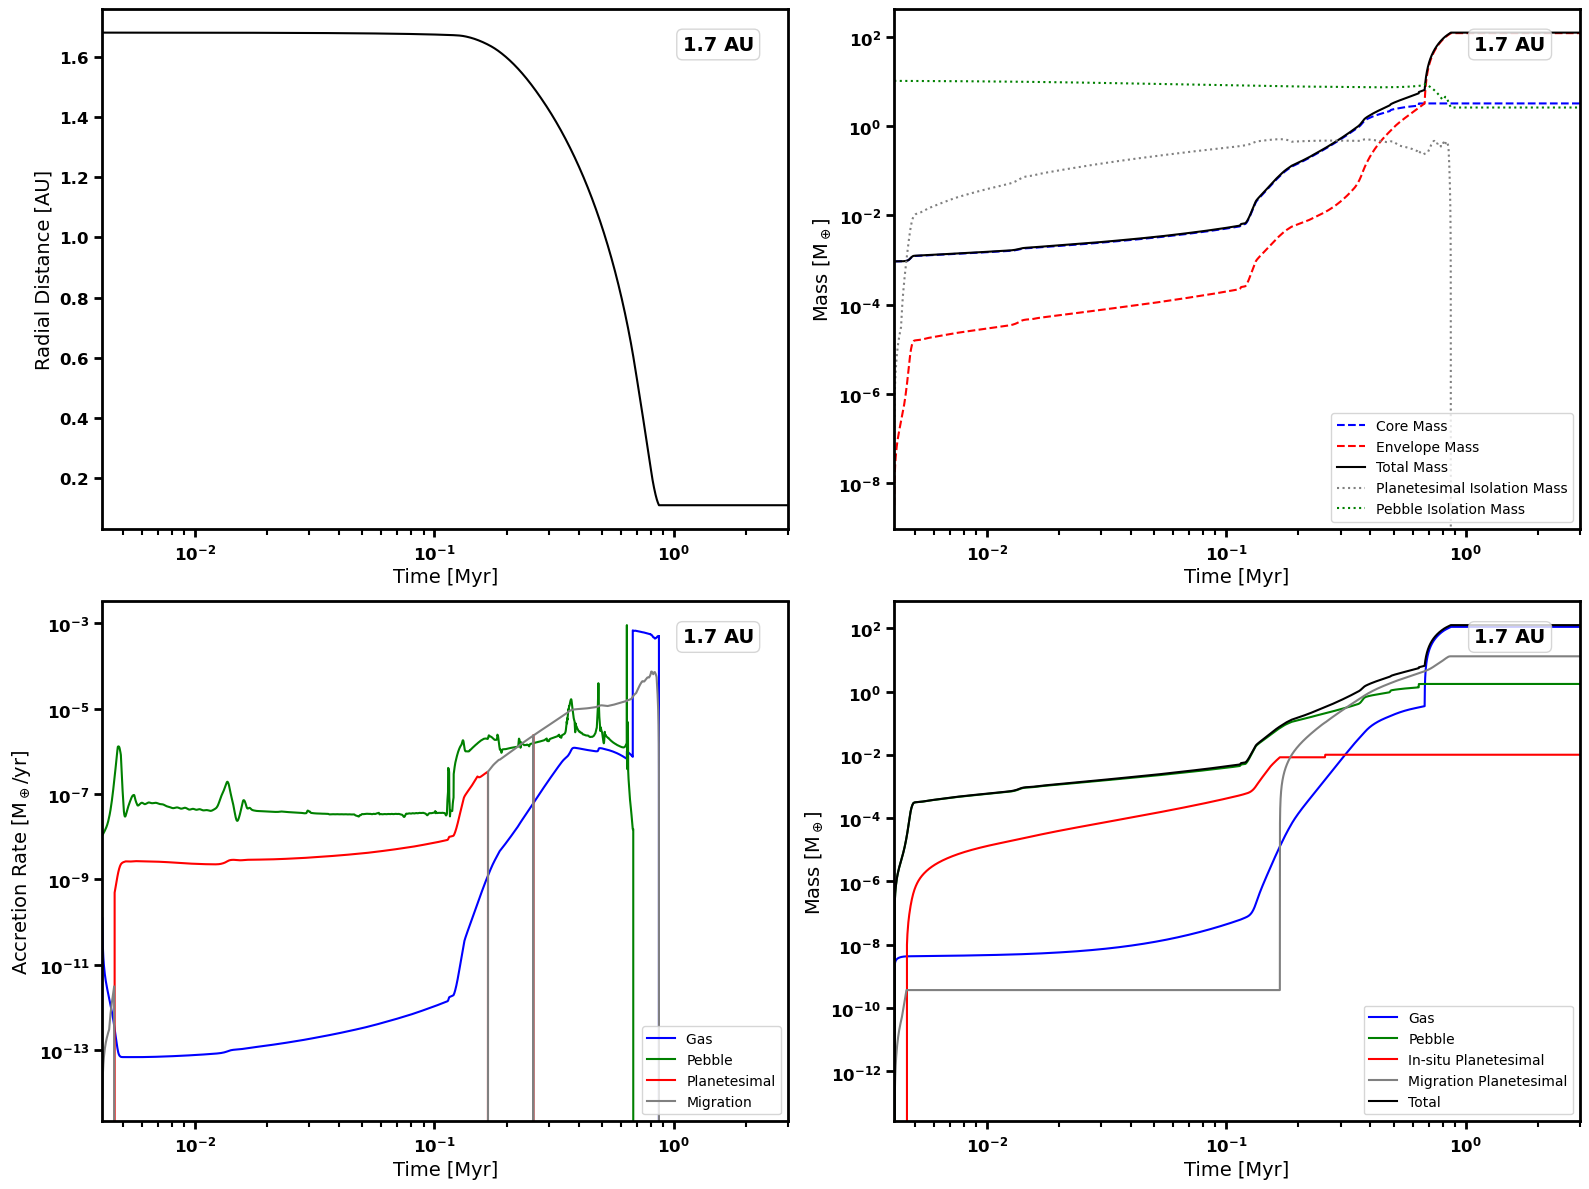

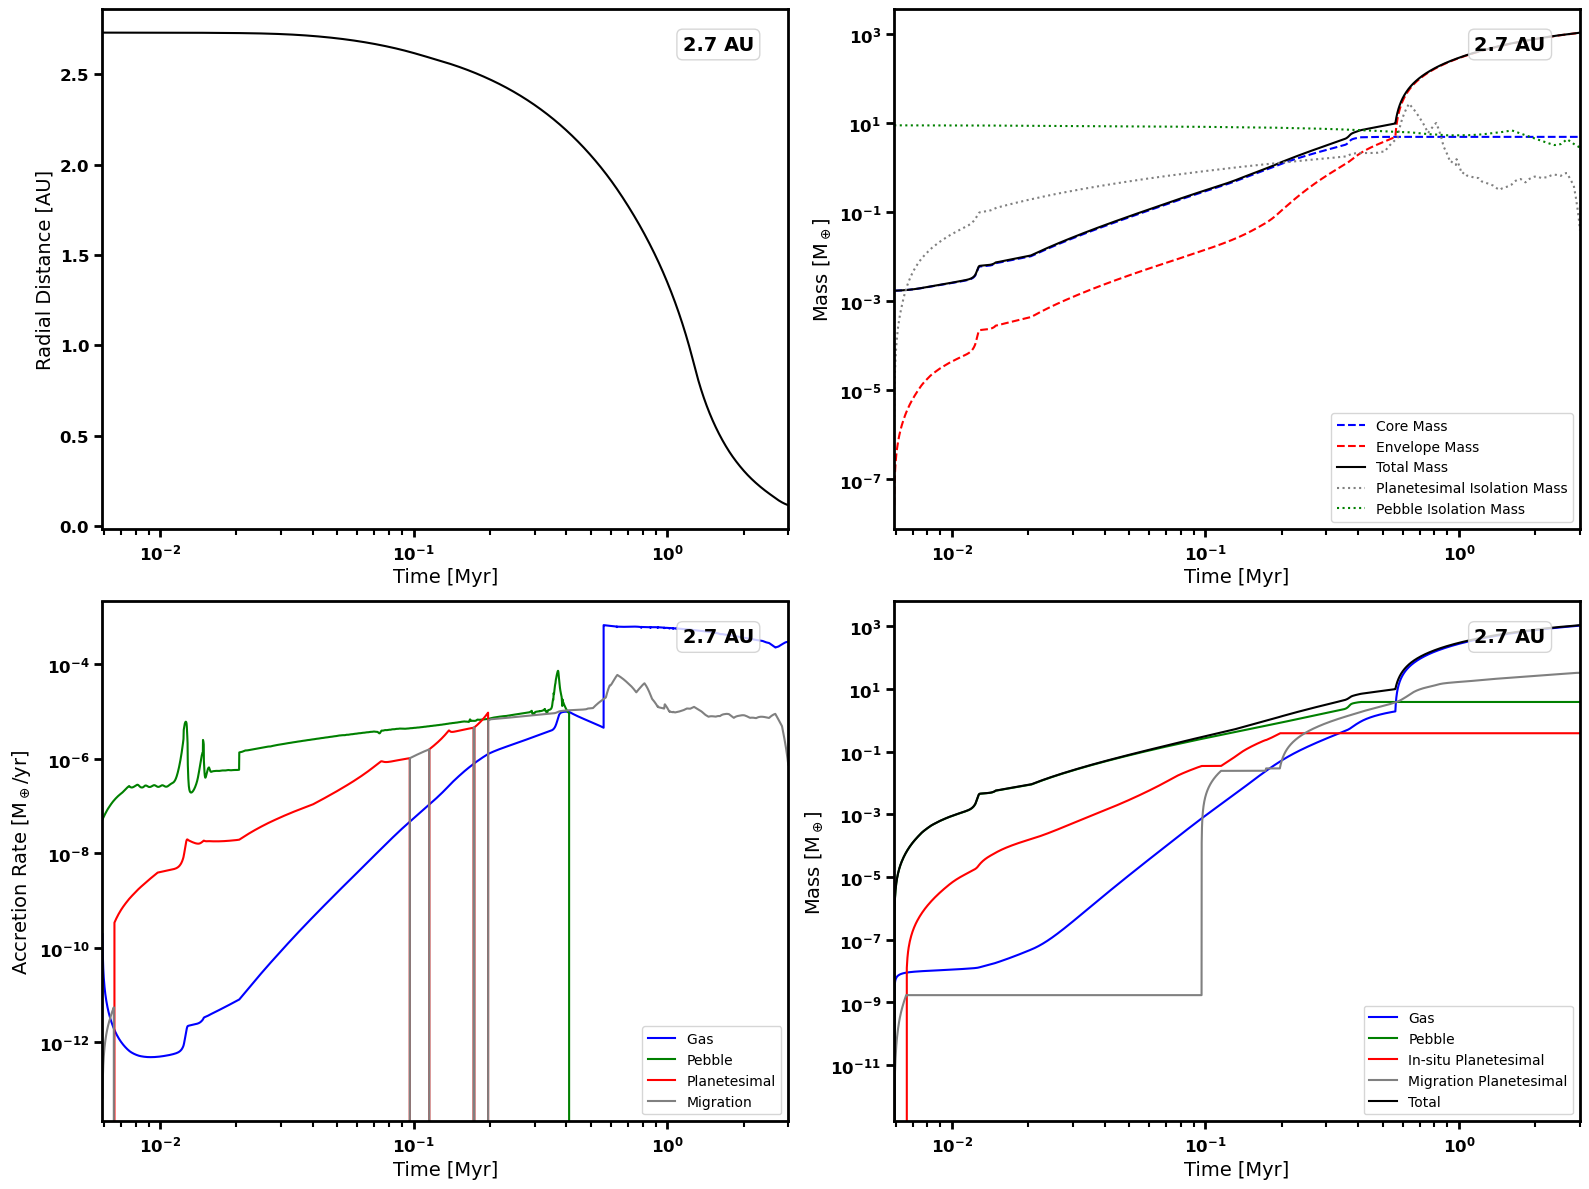

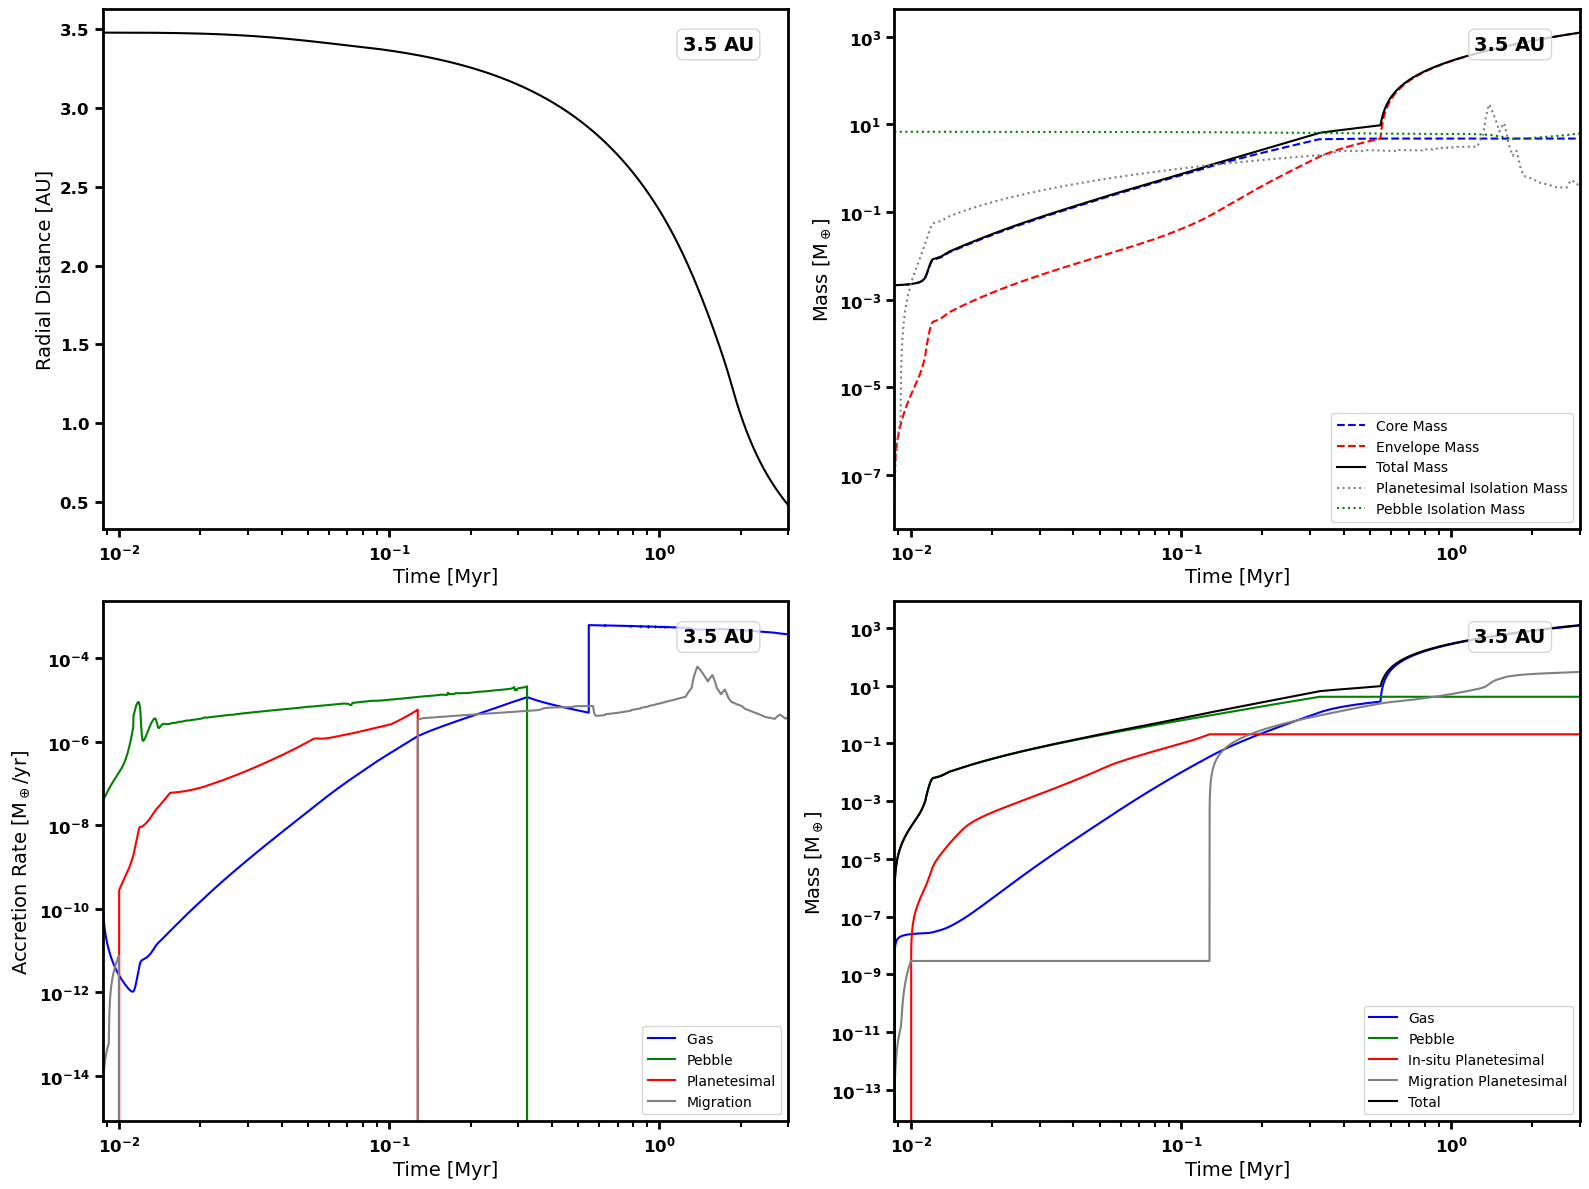

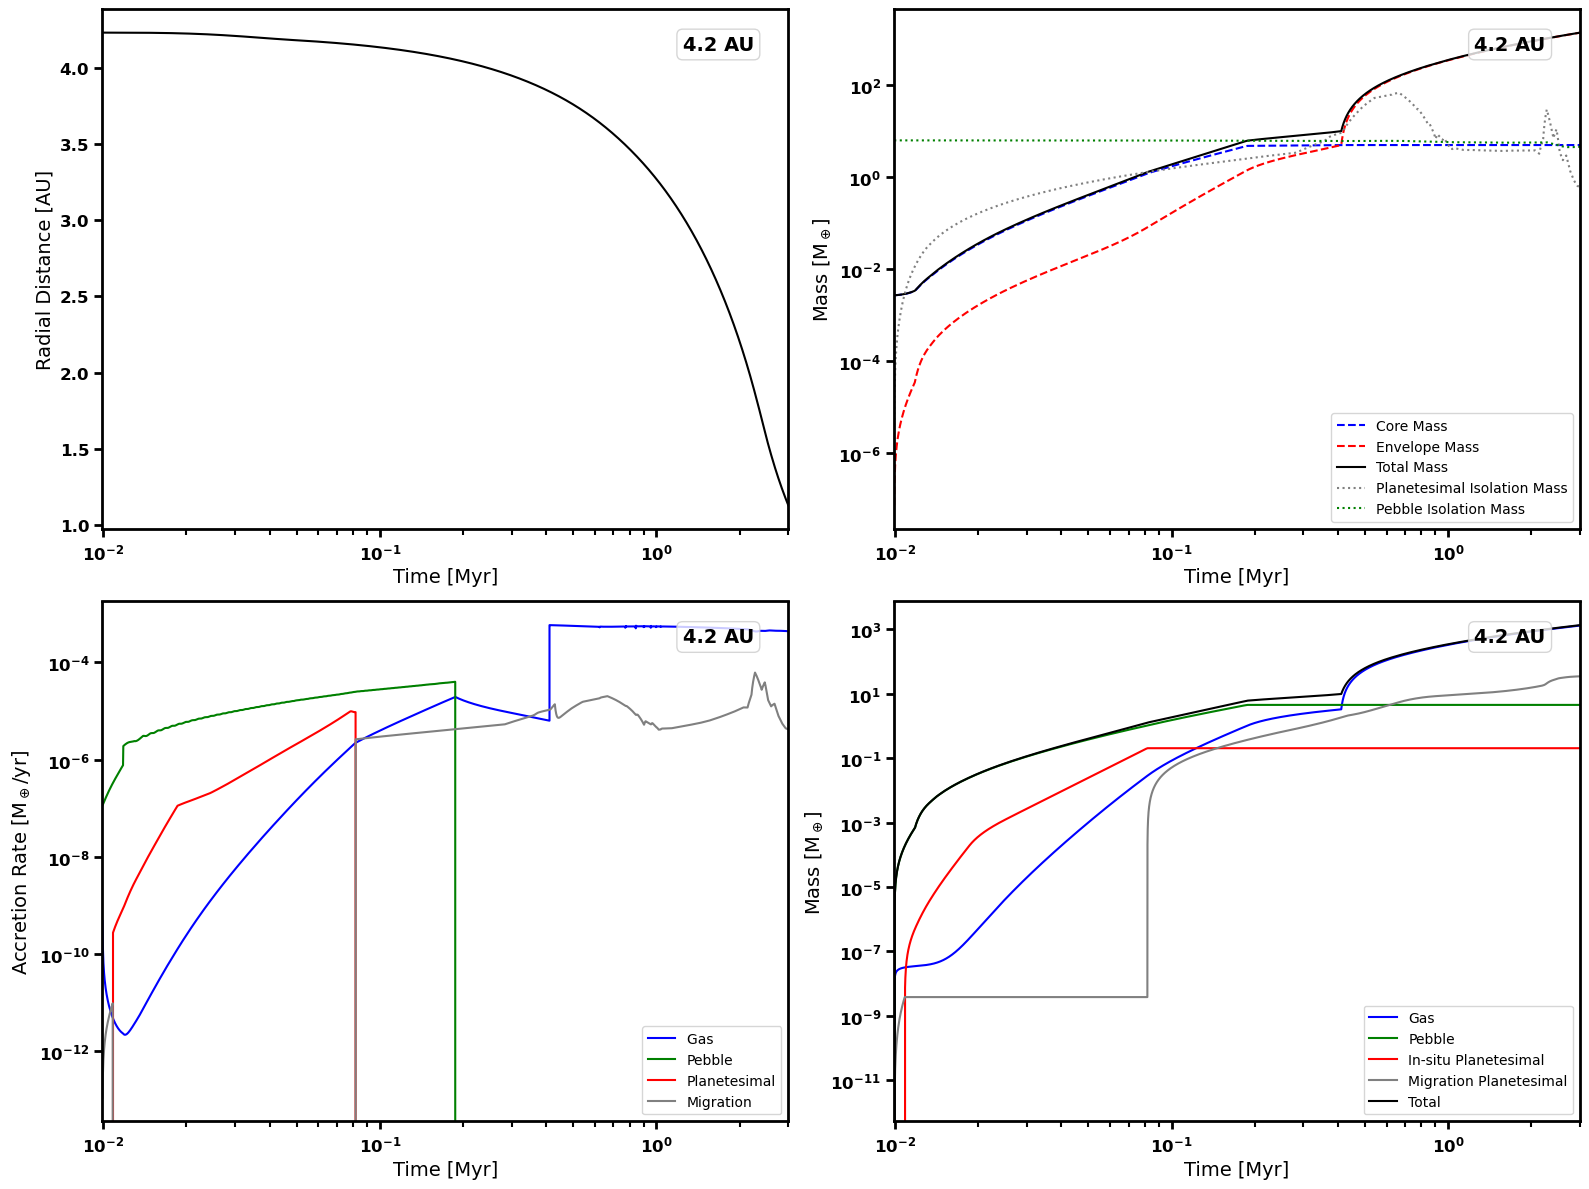

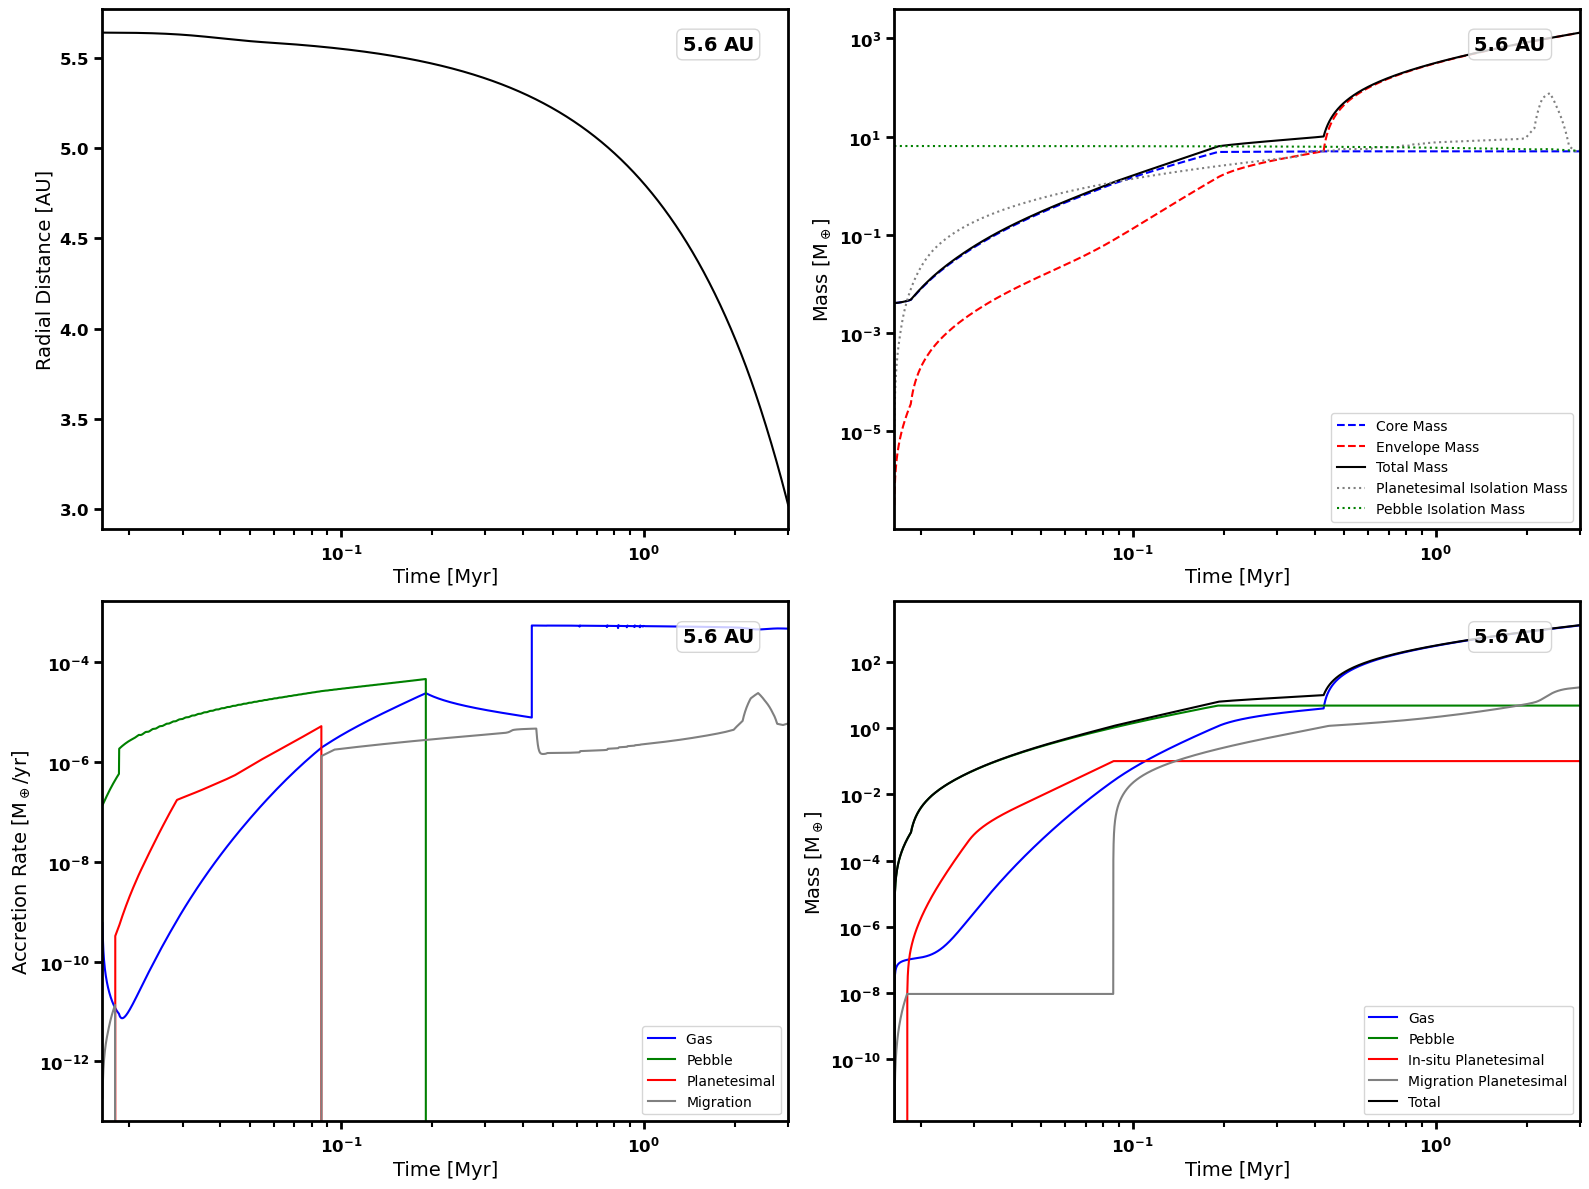

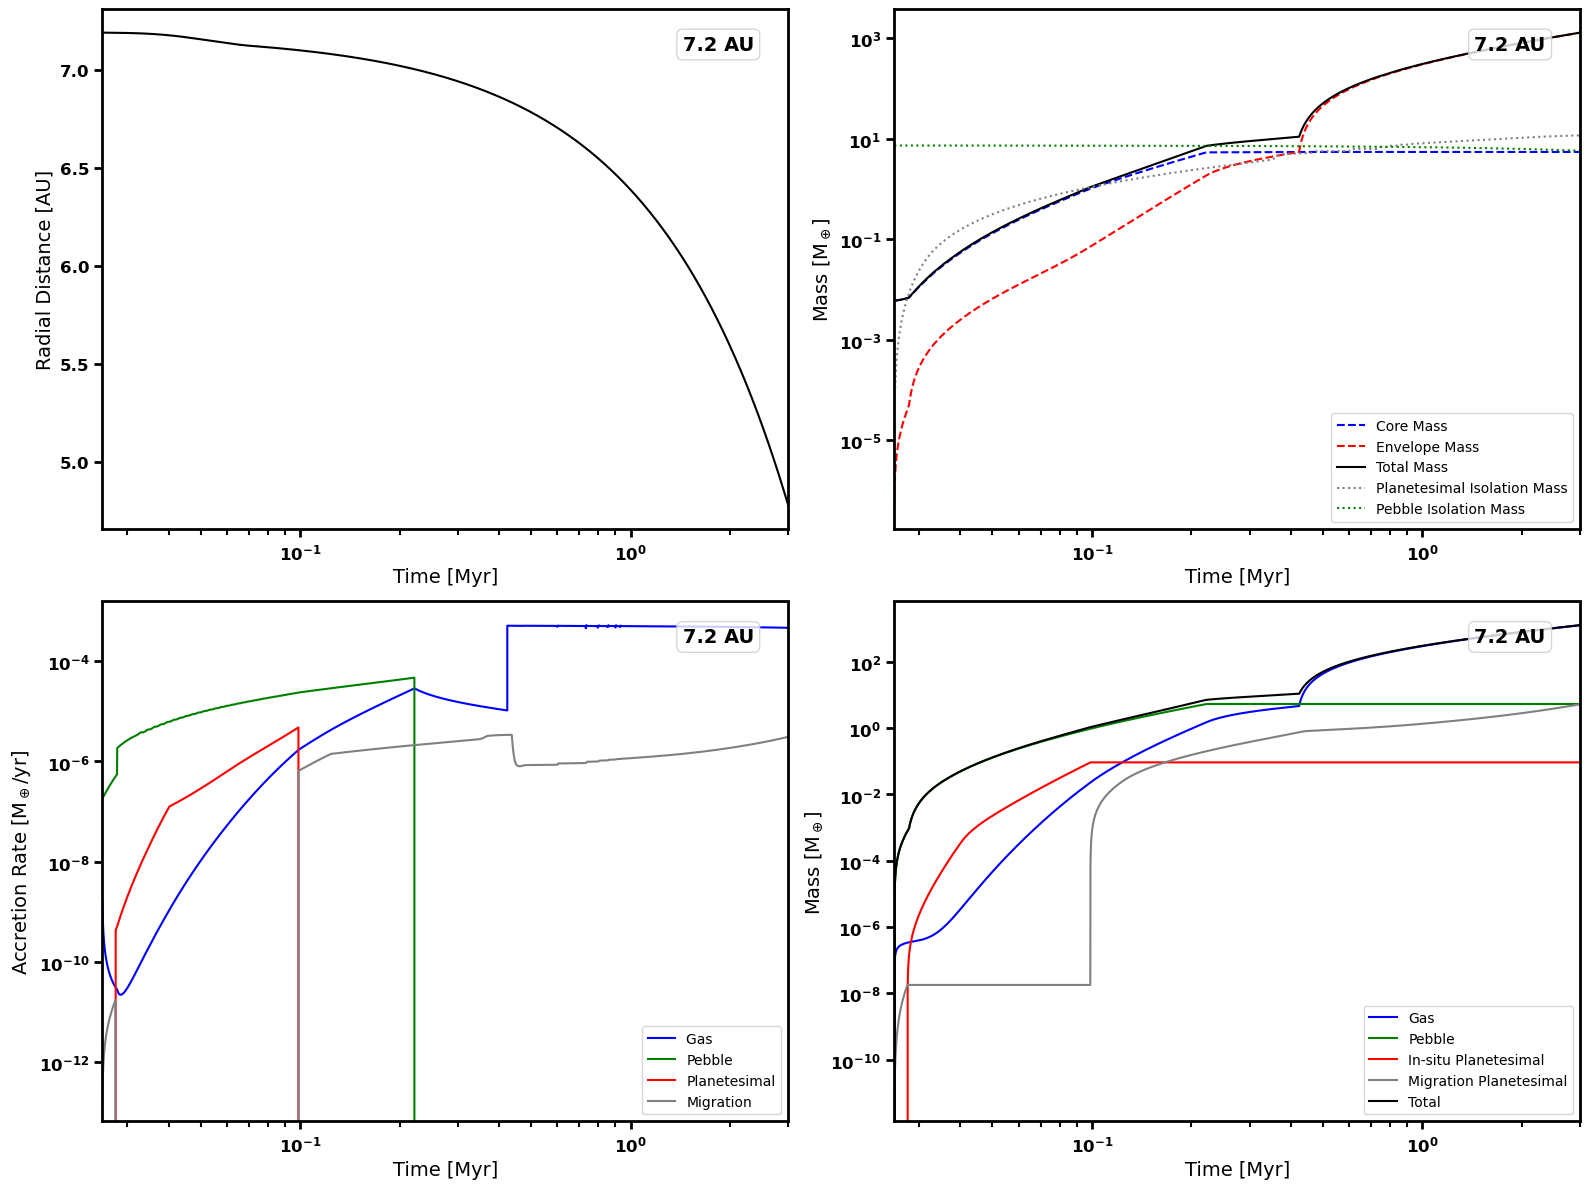

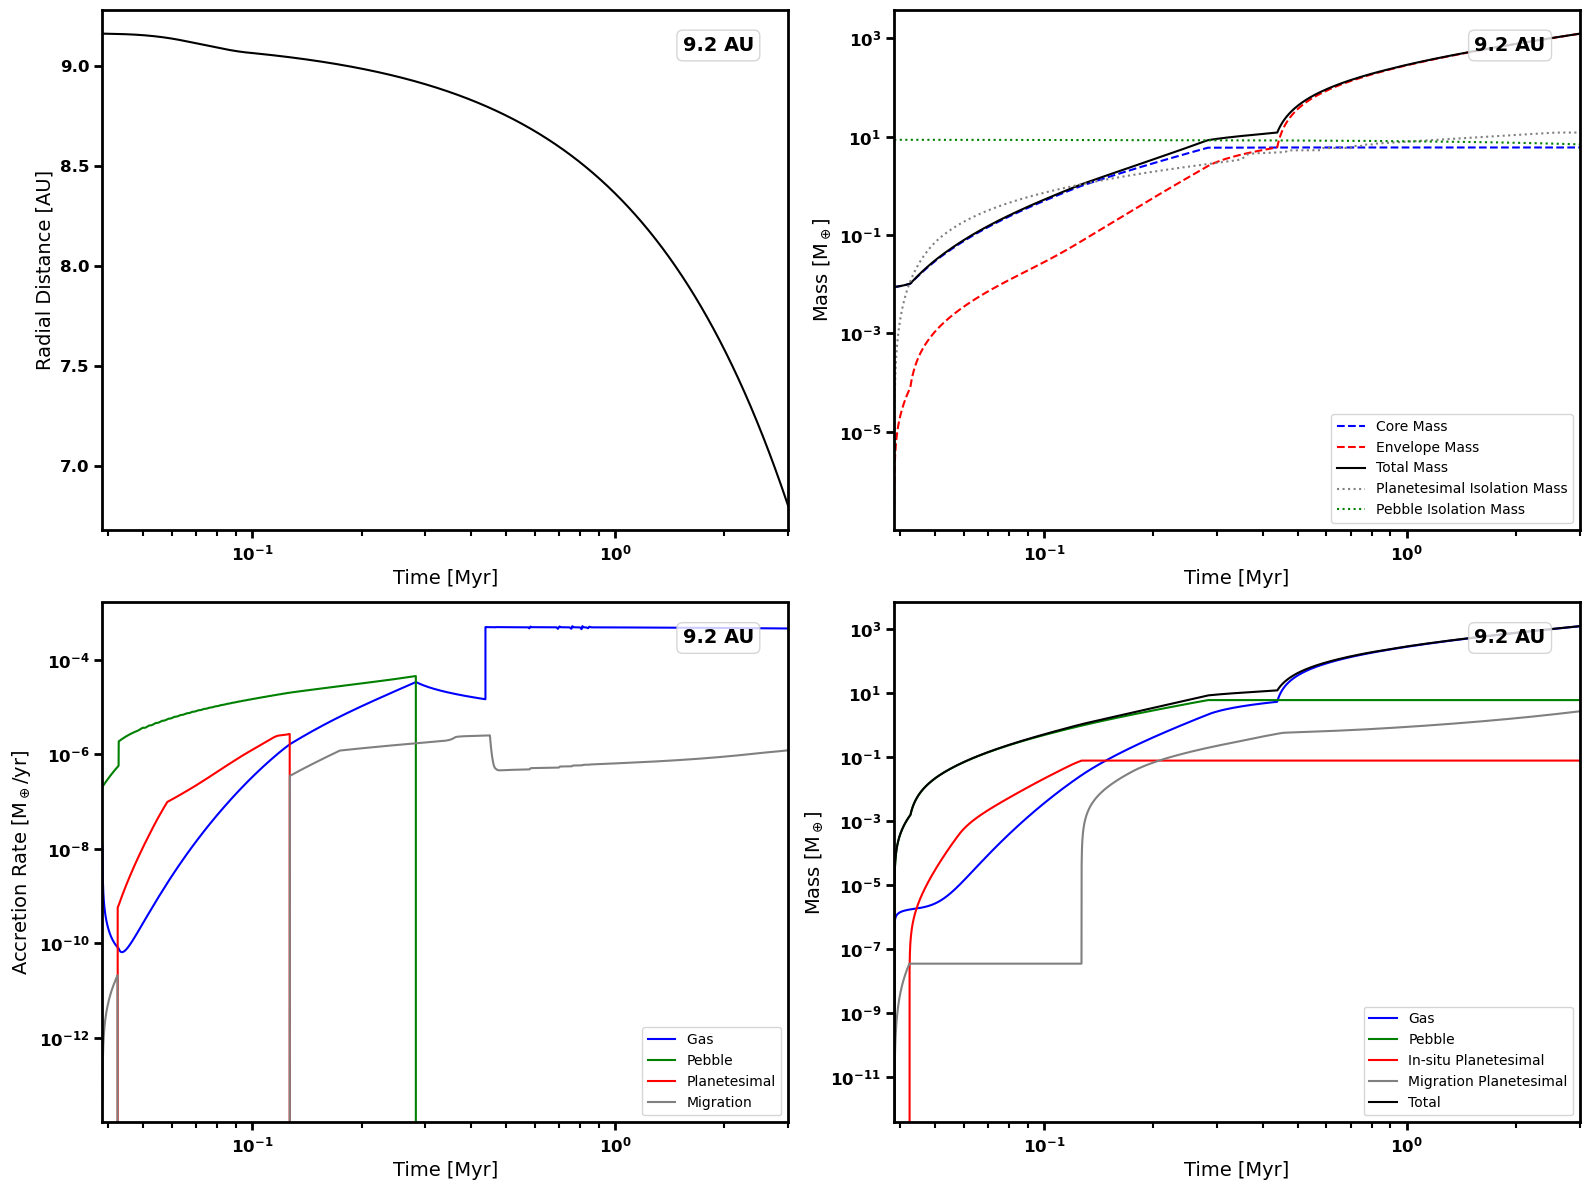

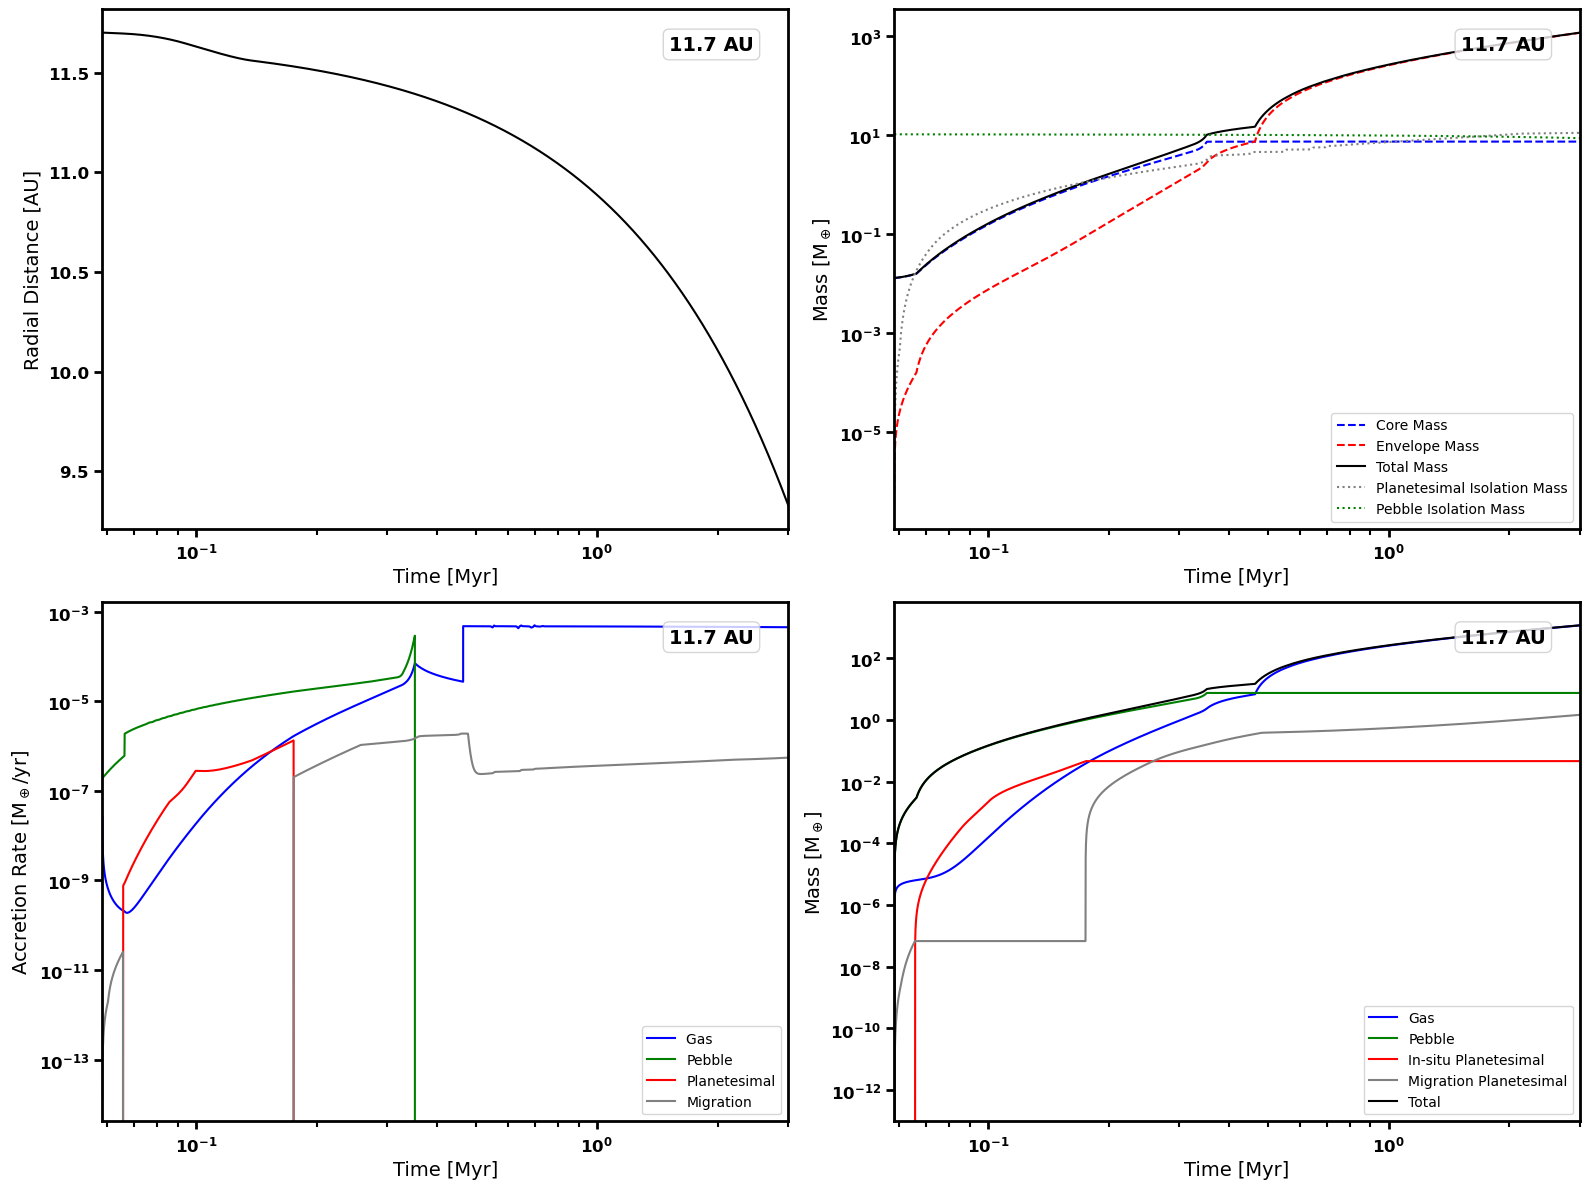

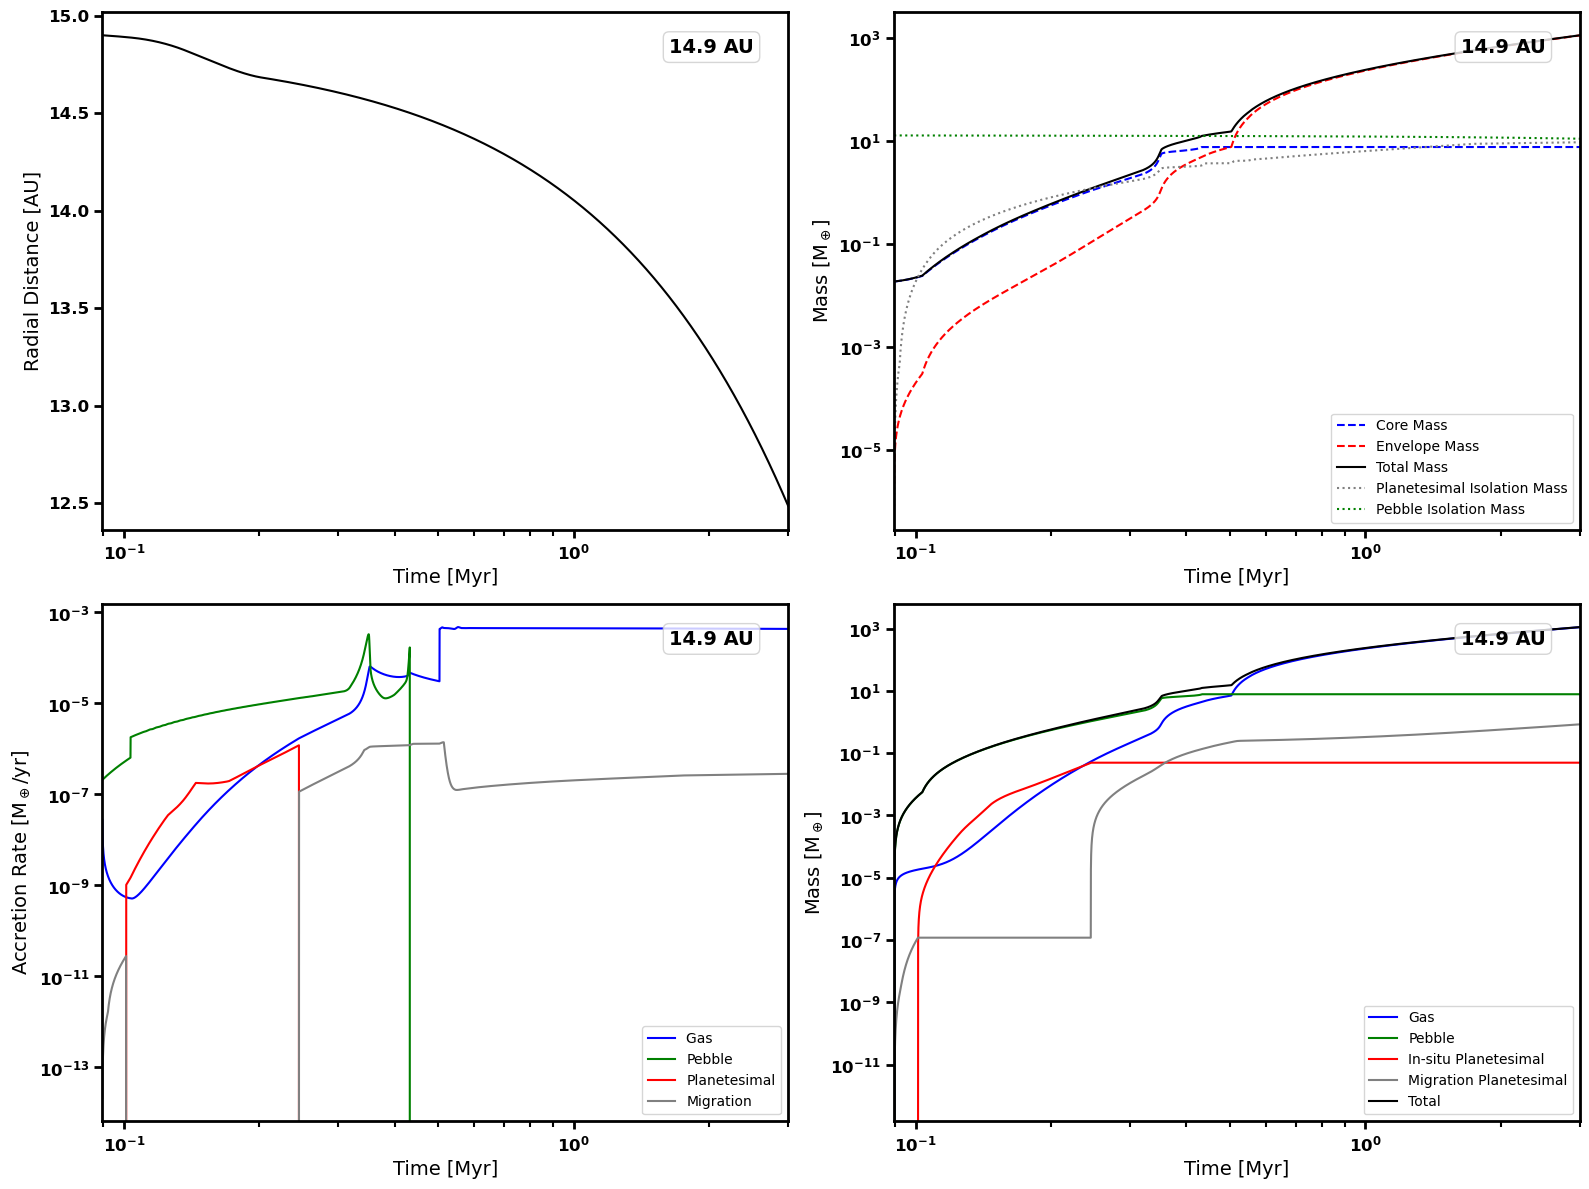

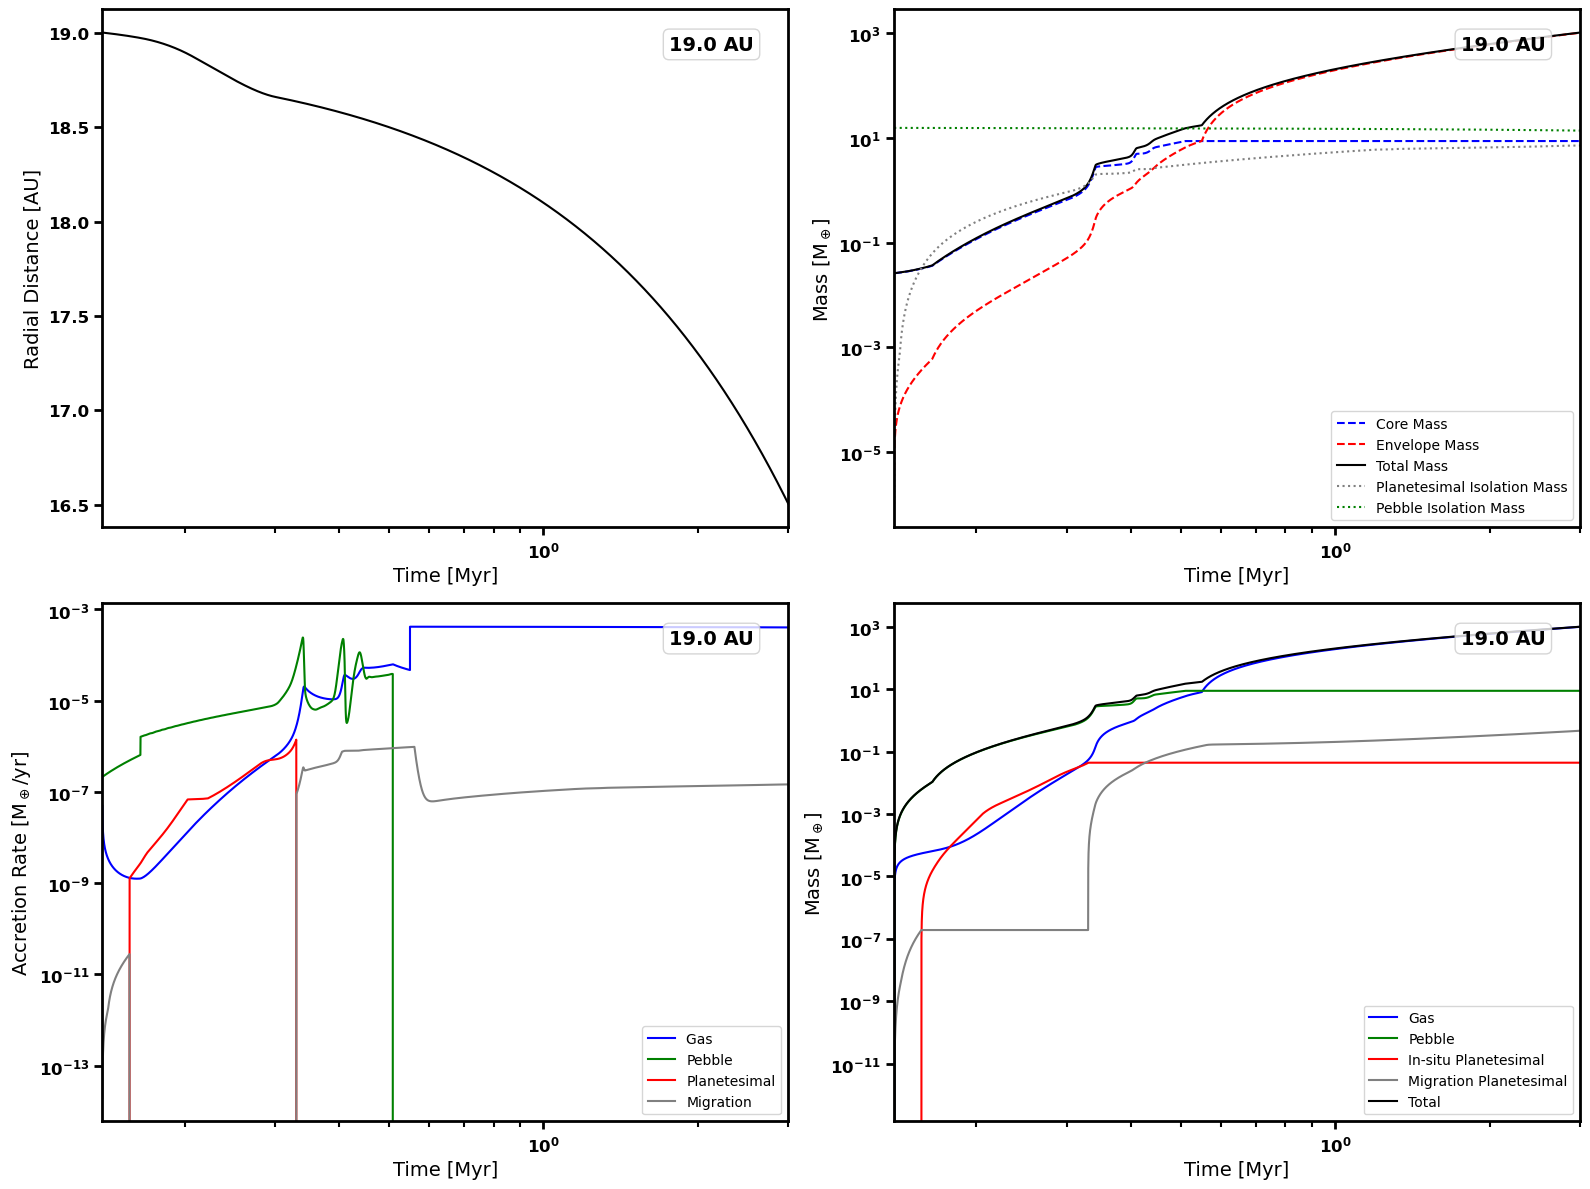

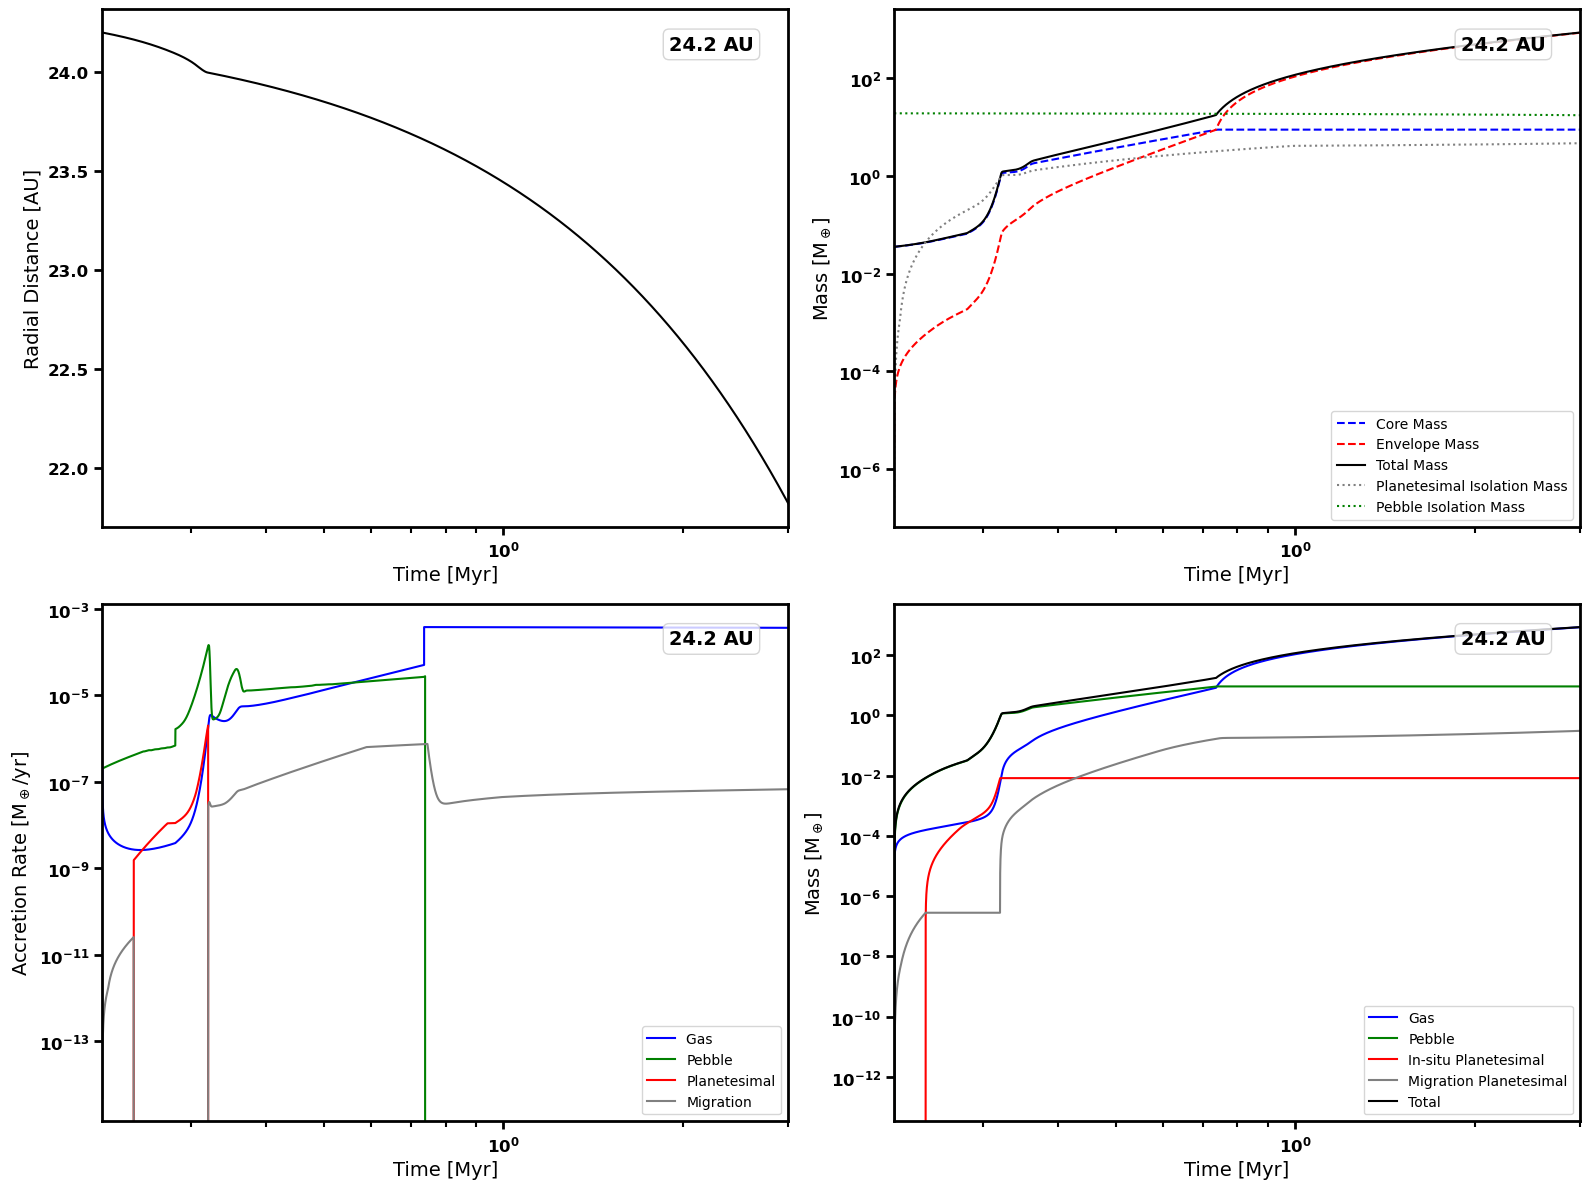

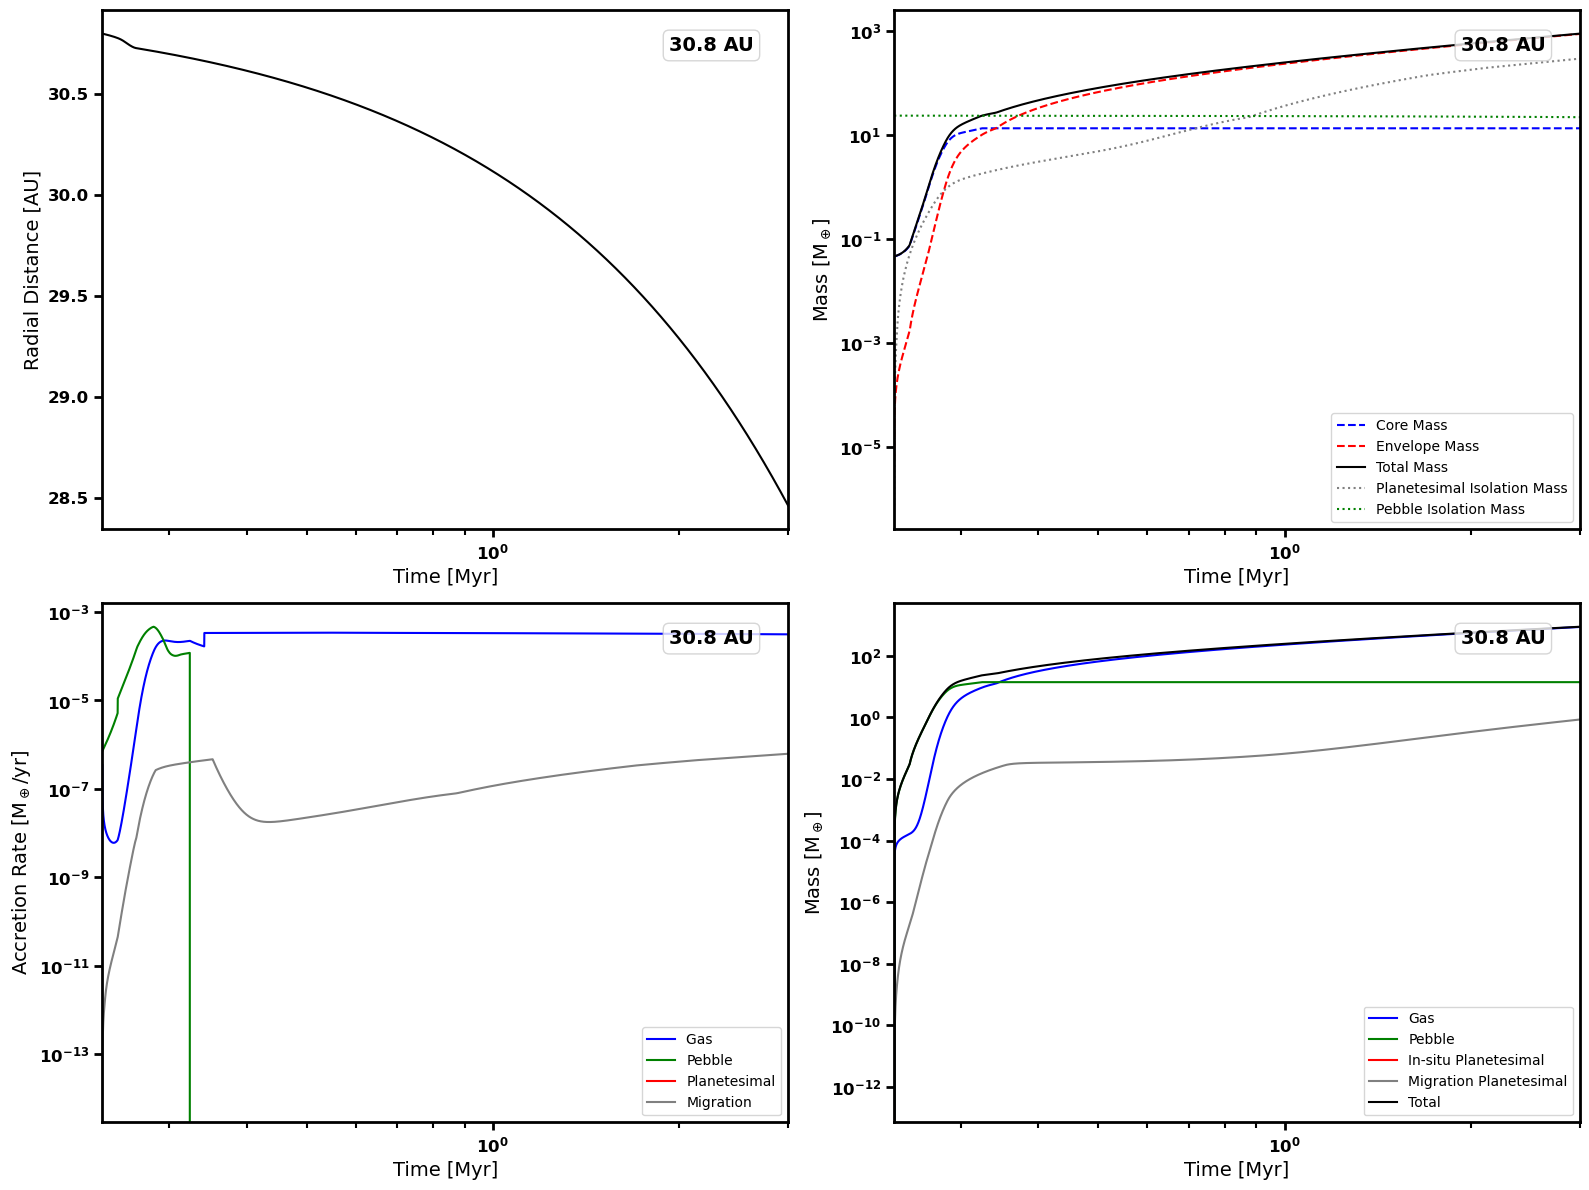

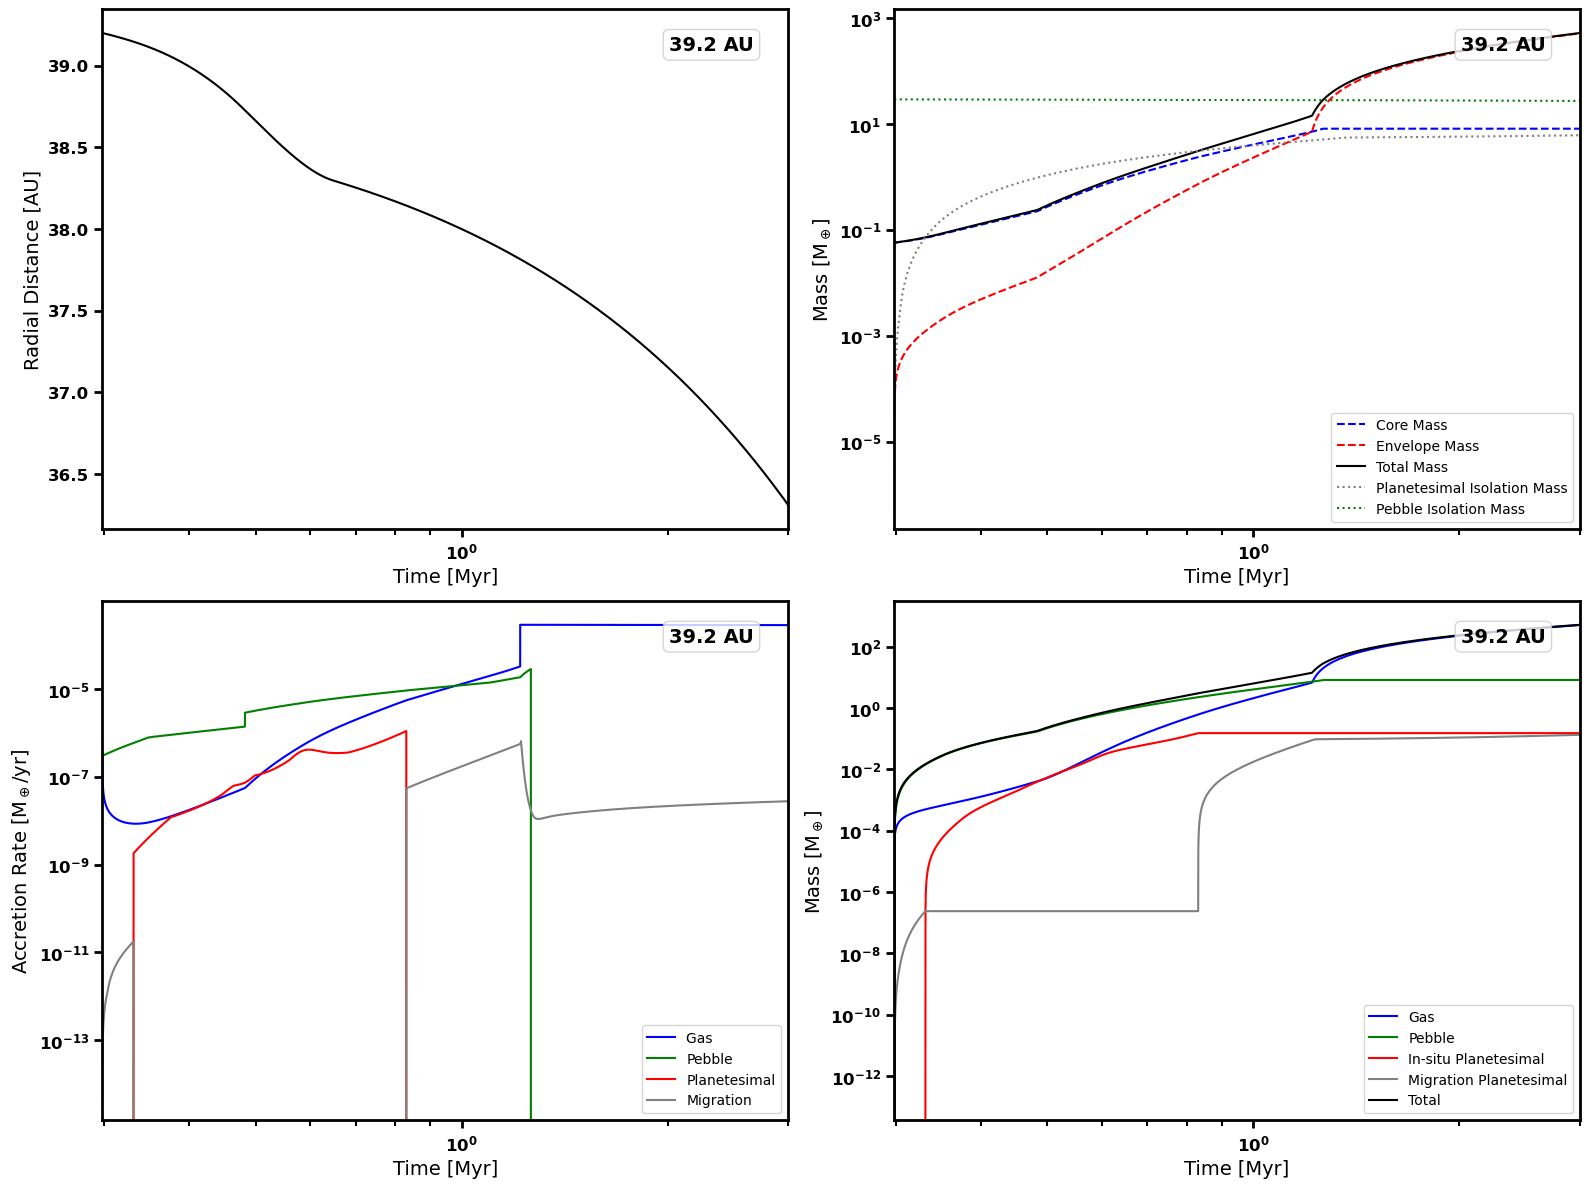

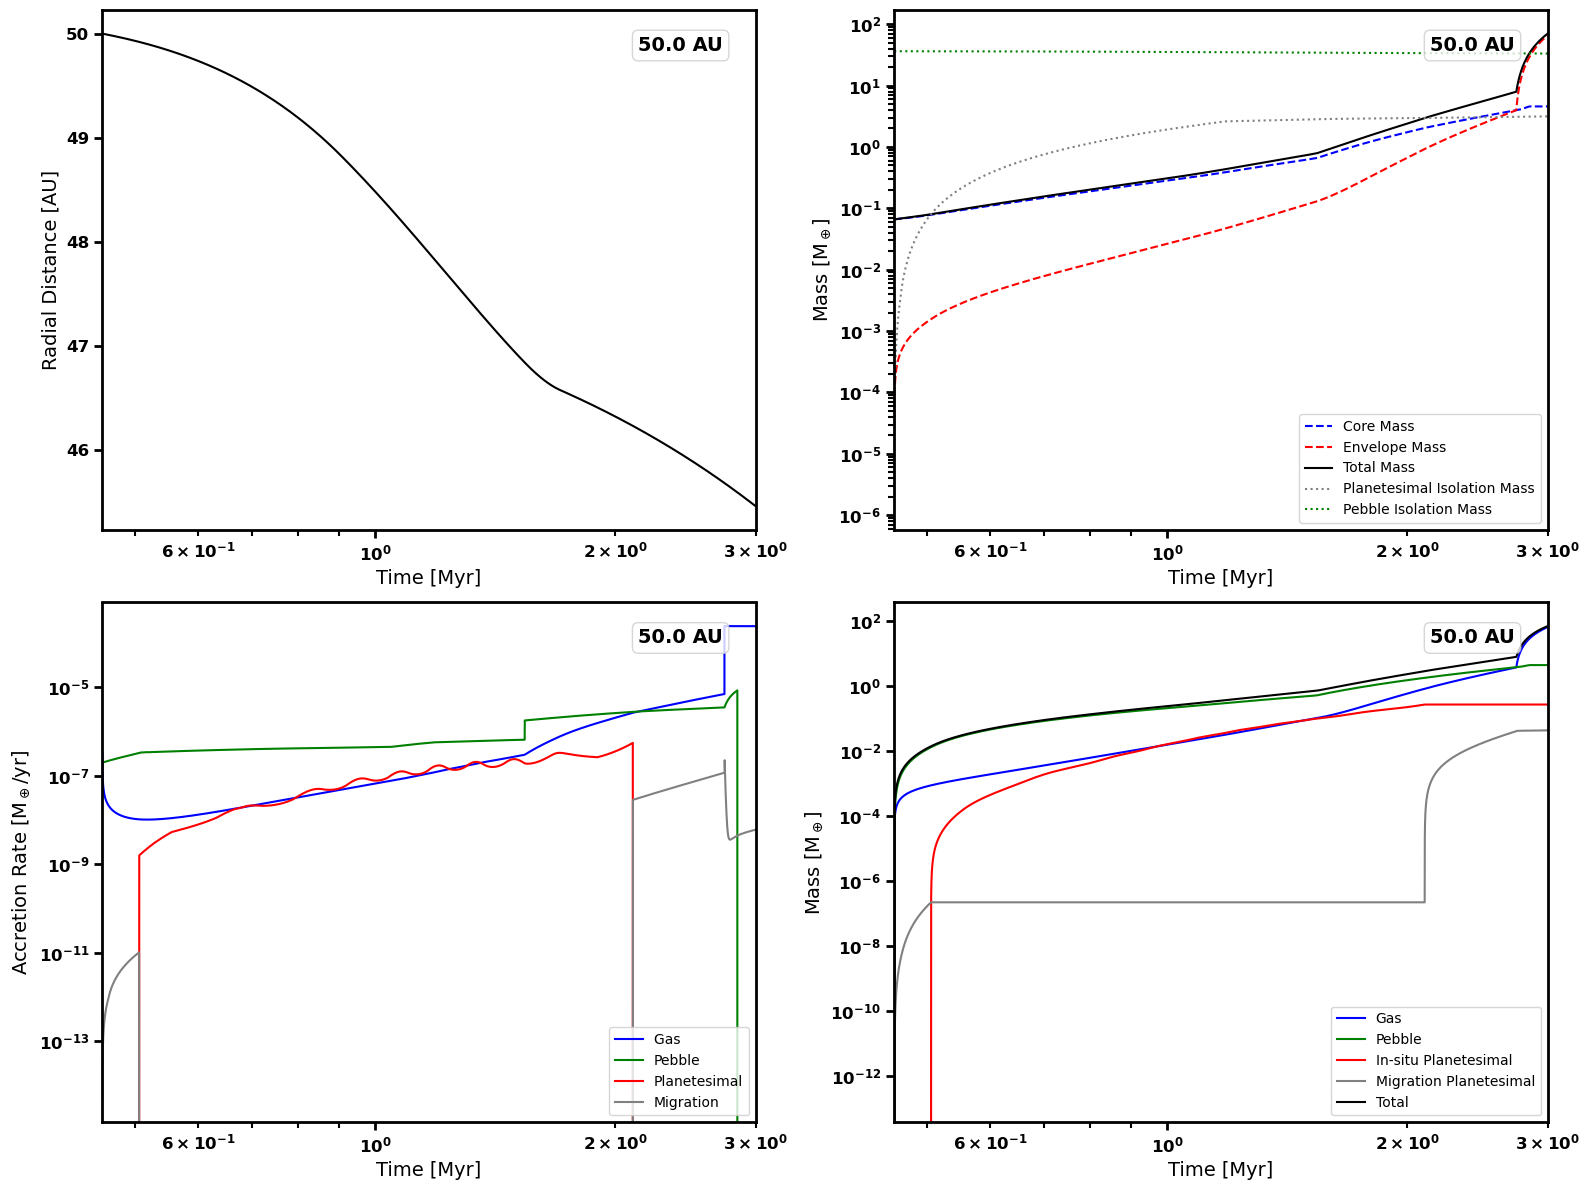

In [14]:
for i in range(n_planets):
    fig, ax = plt.subplots(2, 2, figsize = (8 * 2, 6 * 2))

    ## Planet implanet radius

    valid_R = ~np.isnan(Rp[i])
    
    if np.any(valid_R):
        R_imp = round(Rp[i][valid_R][0], 1)

    ## Radial distance evolution

    ax[0, 0].plot(t / 1e6, Rp[i], color = 'black')

    ax[0, 0].set_xscale('log')
    ax[0, 0].set_xlim([t[~np.isnan(Rp[i])][0] / 1e6, 3])
    ax[0, 0].set_xlabel('Time [Myr]')
    ax[0, 0].set_ylabel('Radial Distance [AU]')

    ax[0, 0].text(0.95, 0.95, f'{R_imp} AU', transform = ax[0, 0].transAxes,
        ha = 'right', va = 'top', fontsize = 14, fontweight = 'bold',
        bbox = dict(boxstyle = 'round', facecolor = 'white', alpha = 0.8, edgecolor = '0.8'))

    ## Mass evolution

    ax[0, 1].plot(t / 1e6, Mcs[i], color = 'blue', linestyle = '--', label = f'Core Mass')
    ax[0, 1].plot(t / 1e6, Mes[i], color = 'red', linestyle = '--', label = f'Envelope Mass')
    ax[0, 1].plot(t / 1e6, Mcs[i] + Mes[i], color = 'black', label = f'Total Mass')

    if config["planets"]["planetesimal_accretion_insitu"]:
        ax[0, 1].plot(t / 1e6, M_iso_planetesimal[i], color = 'grey', linestyle = ':', label = f'Planetesimal Isolation Mass')

    if config["planets"]["pebble_accretion"]:
        ax[0, 1].plot(t / 1e6, M_iso_pebble[i], color = 'green',  linestyle = ':', label = f'Pebble Isolation Mass')

    ax[0, 1].set_xscale('log')
    ax[0, 1].set_yscale('log')
    ax[0, 1].set_xlim([t[~np.isnan(Rp[i])][0] / 1e6, 3])
    ax[0, 1].set_xlabel('Time [Myr]')
    ax[0, 1].set_ylabel(r'Mass [M$_\oplus$]')
    ax[0, 1].legend(loc = 'lower right', fontsize = 10)

    ax[0, 1].text(0.95, 0.95, f'{R_imp} AU', transform = ax[0, 1].transAxes,
        ha = 'right', va = 'top', fontsize = 14, fontweight = 'bold',
        bbox = dict(boxstyle = 'round', facecolor = 'white', alpha = 0.8, edgecolor = '0.8'))

    ## Accretion rate evolution

    if config["planets"]["gas_accretion"]:
        ax[1, 0].plot(t / 1e6, Mdot_gas[i], color = 'blue', label = f'Gas ')

    if config["planets"]["pebble_accretion"]:
        ax[1, 0].plot(t / 1e6, Mdot_pebble_core[i] + Mdot_pebble_env[i], color = 'green', label = f'Pebble')

    if config["planets"]["planetesimal_accretion_insitu"]:
        ax[1, 0].plot(t / 1e6, Mdot_planetesimal[i], color = 'red', label = f'Planetesimal')

    if config["planets"]["planetesimal_accretion_migrate"]:
        ax[1, 0].plot(t / 1e6, Mdot_migration[i], color = 'grey', label = f'Migration')

    ax[1, 0].set_xscale('log')
    ax[1, 0].set_yscale('log')
    ax[1, 0].set_xlim([t[~np.isnan(Rp[i])][0] / 1e6, 3])
    ax[1, 0].set_xlabel('Time [Myr]')
    ax[1, 0].set_ylabel(r'Accretion Rate [M$_\oplus$/yr]')
    ax[1, 0].legend(loc = 'lower right', fontsize = 10)

    ax[1, 0].text(0.95, 0.95, f'{R_imp} AU', transform = ax[1, 0].transAxes,
        ha = 'right', va = 'top', fontsize = 14, fontweight = 'bold',
        bbox = dict(boxstyle = 'round', facecolor = 'white', alpha = 0.8, edgecolor = '0.8'))

    ## Cumulative mass accreted

    M0 = np.nan_to_num(Mcs[i][0], nan = 0.0) + np.nan_to_num(Mes[i][0], nan = 0.0)
    M_tot = np.full_like(t, M0)

    if config["planets"]["gas_accretion"]:
        M_gas_accreted = cumulative_mass_accreted(t, Mdot_gas[i])
        ax[1, 1].plot(t / 1e6, M_gas_accreted, color = 'blue', label = f'Gas')
        M_tot += M_gas_accreted

    if config["planets"]["pebble_accretion"]:
        M_pebble_accreted = cumulative_mass_accreted(t, Mdot_pebble_core[i] + Mdot_pebble_env[i])
        ax[1, 1].plot(t / 1e6, M_pebble_accreted, color = 'green', label = f'Pebble')
        M_tot += M_pebble_accreted

    if config["planets"]["planetesimal_accretion_insitu"]:
        M_planetesimal_accreted = cumulative_mass_accreted(t, Mdot_planetesimal[i])
        ax[1, 1].plot(t / 1e6, M_planetesimal_accreted, color = 'red', label = f'In-situ Planetesimal')
        M_tot += M_planetesimal_accreted

    if config["planets"]["planetesimal_accretion_migrate"]:
        M_migration_accreted = cumulative_mass_accreted(t, Mdot_migration[i])
        ax[1, 1].plot(t / 1e6, M_migration_accreted, color = 'grey', label = f'Migration Planetesimal')
        M_tot += M_migration_accreted

    ax[1, 1].plot(t / 1e6, M_tot, color = 'black', label = f'Total')

    ax[1, 1].set_xscale('log')
    ax[1, 1].set_yscale('log')
    ax[1, 1].set_xlim([t[~np.isnan(Rp[i])][0] / 1e6, 3])
    ax[1, 1].set_xlabel('Time [Myr]')
    ax[1, 1].set_ylabel(r'Mass [M$_\oplus$]')
    ax[1, 1].legend(loc = 'lower right', fontsize = 10)

    ax[1, 1].text(0.95, 0.95, f'{R_imp} AU', transform = ax[1, 1].transAxes,
        ha = 'right', va = 'top', fontsize = 14, fontweight = 'bold',
        bbox = dict(boxstyle = 'round', facecolor = 'white', alpha = 0.8, edgecolor = '0.8'))

    bold_ticks(*ax.flat)

    plt.tight_layout()

    if save_figures:
        os.makedirs(f'{figure_dir}/planet_evolution/', exist_ok = True)
        figure_path = os.path.join(f'{figure_dir}/planet_evolution/', f"planet_evolution_{R_imp}AU.png")
        plt.savefig(figure_path)

    plt.show()

## Planet Growth Tracks

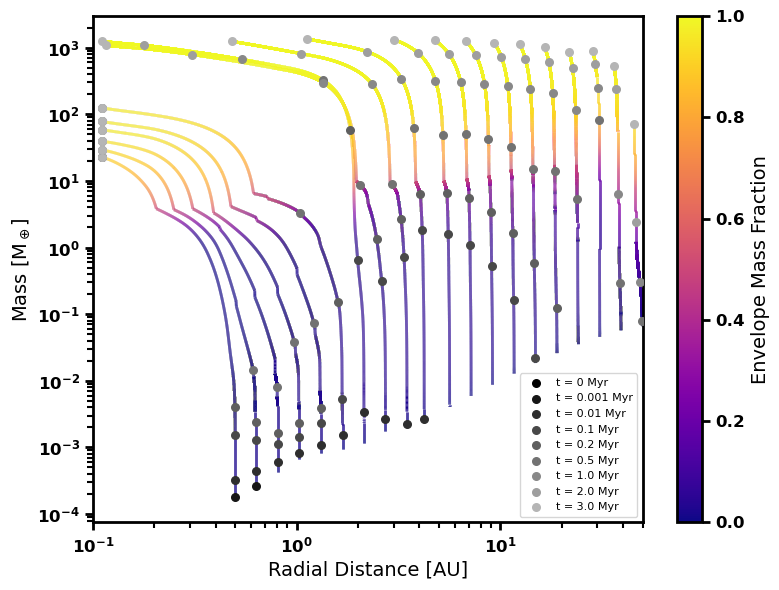

In [15]:
fig, ax = plt.subplots(figsize = (8, 6))

cmap = plt.get_cmap('plasma')
norm = Normalize(vmin = 0, vmax = 1)

for i in range(n_planets):
    x = Rp[i]
    y = Mcs[i] + Mes[i]
    frac = Mes[i] / y

    ## Plot growth tracks with color indicating envelope mass fraction

    points = np.array([x, y]).T.reshape(-1, 1, 2)
    segments = np.concatenate([points[:-1], points[1:]], axis = 1)

    lc = LineCollection(segments, cmap = cmap, norm = norm)
    lc.set_array(frac)
    lc.set_linewidth(2)
    line = ax.add_collection(lc)

    ## Add time interval markers to growth tracks

    for j in range(n_times):
        k = np.array([np.argmin(np.abs(t / 1e6 - t_interval[j]))])

        if i == 0:
            label = f't = {t_interval[j]} Myr'
            
        else:
            label = None

        ax.scatter(Rp[i][k], y[k], color = color_greys[j], s = 30, zorder = 3, label = label)

ax.set_xlim(1e-1, 1e2 / 2)
ax.set_xscale('log')
ax.set_yscale('log')
ax.autoscale_view(scalex = False, scaley = True)
ax.set_xlabel('Radial Distance [AU]')
ax.set_ylabel(r'Mass [M$_\oplus$]')

cbar = fig.colorbar(line, ax = ax)
cbar.set_label('Envelope Mass Fraction')

bold_ticks(ax, cbar.ax)

plt.legend(loc = 'lower right', fontsize = 8)

plt.tight_layout()

if save_figures:
    figure_path = os.path.join(figure_dir, f"planet_growth_tracks.png")
    plt.savefig(figure_path)

plt.show()

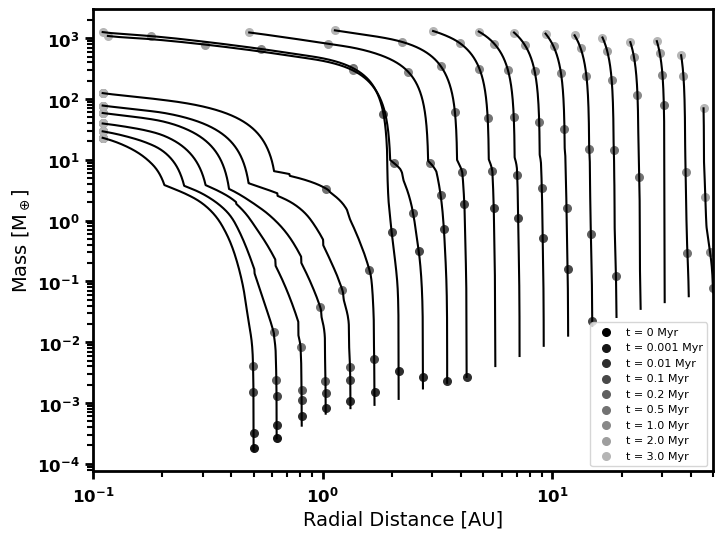

In [16]:
fig, ax = plt.subplots(figsize = (8, 6))

for i in range(n_planets):
    ax.plot(Rp[i], Mcs[i] + Mes[i], color = 'black')

    ## Add time interval markers to growth tracks

    for j in range(n_times):
        k = np.array([np.argmin(np.abs(t / 1e6 - t_interval[j]))])

        if i == 0:
            label = f't = {t_interval[j]} Myr'
            
        else:
            label = None
            
        ax.scatter(Rp[i][k], Mcs[i][k] + Mes[i][k], color = color_greys[j], s = 30, label = label)

ax.set_xlim(1e-1, 1e2 / 2)
ax.set_xscale('log')
ax.set_yscale('log')
ax.set_xlabel('Radial Distance [AU]')
ax.set_ylabel(r'Mass [M$_\oplus$]')

bold_ticks(ax)

plt.legend(loc = 'lower right', fontsize = 8)

plt.show()

## Helper Functions

In [17]:
## Streaming instability birth mass

def M_birth(R, Sigma_G, T):
    """Calculates the streaming instability brith mass in Earth masses (equation 8 from Johnston et al 2026)."""
    M_star = config["star"]["M"]
    return 6e-2 * (gamma(R, Sigma_G, T) * np.pi) ** 1.5 * (H(R, T) / R / 0.05) ** 3 * (M_star / 2.4)

def M_birth_pltsml(R, Sigma_G, T):
    """Calculates the streaming instability birth mass of planetesimals in Earth masses (equation 13 from Liu et al 2020)."""
    Z = config["disc"]["d2g_SI"]
    M_star = config["star"]["M"]
    h = H(R, T) / R
    return 5e-6 * (Z / 0.02) ** 0.5 * (gamma(R, Sigma_G, T) * np.pi) ** 1.5 * (h / 0.05) ** 3 * (M_star / 0.1)

def M_birth_embryo(R, Sigma_G, T):
    """Calculates the streaming instability birth mass of embryos in Earth masses (equation 14 from Liu et al 2020)."""
    f_plt = config["planets"]["f_plt"]
    return f_plt * M_birth_pltsml(R, Sigma_G, T)

def gamma(R, Sigma_G, T):
    """Calculates the self-gravity parameter (Johnston et al 2026)."""
    G = 6.67430e-8
    return 4 * np.pi * G * rho_mid(R, Sigma_G, T) / (Omega_K(R) ** 2)

## Pebble accretion onset mass

def M_on(R, Sigma_G, T):
    """Calculates the onset mass for pebble accretion in Earth masses (Lorek et al 2022)."""
    M_star = 1.0  # in units of Msun
    R_star = 1.0 * Rsun
    T_eff = 4000
    L_star = 4 * np.pi * R_star ** 2 * sig_SB * T_eff ** 4 / Lsun
    return 4.871e-7 * (tau_s(R, Sigma_G, T) / 0.01) * M_star ** (-17/7) * L_star ** (6/7) * R ** (12/7)

def tau_s(R, Sigma_G, T):
    """Calculates the Stokes number (Lorek et al 2022)."""
    return np.min((tau_s_frag(T), tau_s_drift(R, Sigma_G, T)), axis = 0)

def tau_s_frag(T):
    """Calculates the fragmentation limited Stokes number (Lorek et al 2022)."""
    v_frag = 500
    return v_frag ** 2 / (2 * alpha * c_s(T) ** 2)

def tau_s_drift(R, Sigma_G, T):
    """Calculates the drift limited Stokes number (Lorek et al 2022)."""
    epsilon_g = 0.5
    d2g = 0.01
    return 3 * np.sqrt(np.pi) / 4 * epsilon_g * d2g / eta(R, Sigma_G, T)

def eta(R, Sigma_G, T):
    """Calculates the eta parameter (Fortier et al 2012)."""
    return -1 * dP_dR(R, Sigma_G, T) / (2 * Omega_K(R) ** 2 * R * AU * rho_mid(R, Sigma_G, T))

## Pebble accretion transition mass

def M_tr(R):
    """Calculates the transition mass from the Bondi to the Hill regime in Earth masses (Lorek et al 2022)."""
    M_star = 1.0  # in units of Msun
    R_star = 1.0 * Rsun
    T_eff = 4000
    L_star = 4 * np.pi * R_star ** 2 * sig_SB * T_eff ** 4 / Lsun
    return 1.125e-4 * M_star ** (-17/7) * L_star ** (6/7) * R ** (12/7)

## Pebble isolation mass

def M_iso_peb(R, Sigma_G, T):
    """Calculates the pebble isolation mass in Earth masses (Lorek et al 2022)."""
    return 25 * (H(R, T) / R / 0.05) ** 3 * (0.34 * (-3 / np.log10(alpha)) ** 4 + 0.66 ) * (1 - (dlnP_dlnR(R, Sigma_G, T) + 2.5) / 6)

## Planetesimal isolation mass

def M_iso_pltsml(R, Sigma_plantesimal):
    """Calculates the planetesimal isolation mass in Earth masses (Rafikov 2011)."""
    b_tilde = 10
    M_star = 1.0 * Msun
    return (2 * np.pi * (R * AU) ** 2 * b_tilde * Sigma_plantesimal) ** (3/2) * (3 * M_star) ** (-1/2) / Mearth

## Physical radius

def R_phys(M):
    """Convert planetesimal mass (Earth masses) to physical radius (km), assuming a constant density."""
    rho = config["planets"]["rho_core"] # g/cm^3
    return (3 * M * Mearth / (4 * np.pi * rho)) ** (1 / 3) / 1e5 # km

## Birth Mass Profile

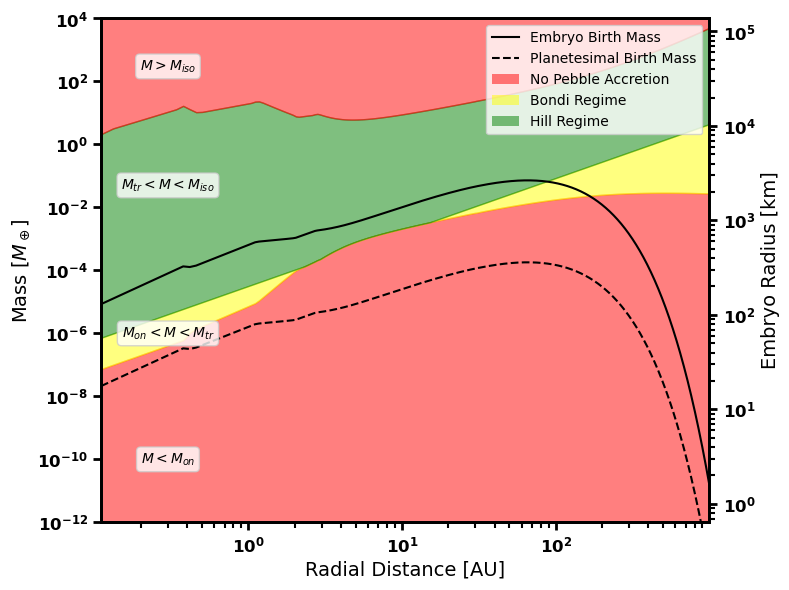

In [18]:
M_birth_embryo_vals = M_birth_embryo(R, Sigma_G[0], T[0])
M_birth_pltsml_vals = M_birth_pltsml(R, Sigma_G[0], T[0])
M_on_vals = M_on(R, Sigma_G[0], T[0])
M_tr_vals = M_tr(R)
M_iso_peb_vals = M_iso_peb(R, Sigma_G[0], T[0])

fig, ax = plt.subplots(figsize = (8, 6))

ax.set_xscale('log')
ax.set_yscale('log')
ax.set_ylim(1e-12, 1e4)
ax.margins(0)
ax.set_xlabel(r'Radial Distance [AU]')
ax.set_ylabel(r'Mass [$M_\oplus$]')

## Fill regions between pebble accretion regimes

b0 = np.full_like(R, 1e-12)
b1 = np.maximum(b0, M_on_vals)
b2 = np.maximum(b1, M_tr_vals)
b3 = np.maximum(b2, M_iso_peb_vals)
b4 = np.full_like(R, 1e4)

ax.fill_between(R, b0, b1, color = 'red', alpha = 0.5)
ax.fill_between(R, b1, b2, color = 'yellow', alpha = 0.5)
ax.fill_between(R, b2, b3, color = 'green', alpha = 0.5)
ax.fill_between(R, b3, b4, color = 'red', alpha = 0.5)

## Birth mass lines

## Birth mass lines

embryo_birth_line, = ax.plot(R, M_birth_embryo_vals, color = 'black', label = 'Embryo Birth Mass')
handles = [embryo_birth_line]

if config["planetesimal"]["active"]:
    M_birth_pltsml_vals = M_birth_pltsml(R, Sigma_G[0], T[0])
    pltsml_birth_line, = ax.plot(R, M_birth_pltsml_vals, color = 'black', linestyle = 'dashed', label = 'Planetesimal Birth Mass')
    handles.append(pltsml_birth_line)

## Annotate pebble accretion regimes

ax.text(3e-1, 1e-10, r'$M < M_{on}$', ha = 'center', va = 'center', bbox = dict(boxstyle = 'round', facecolor = 'white', alpha = 0.8, edgecolor = '0.8'))
ax.text(3e-1, 1e-6, r'$M_{on} < M < M_{tr}$', ha = 'center', va = 'center', bbox = dict(boxstyle = 'round', facecolor = 'white', alpha = 0.8, edgecolor = '0.8'))
ax.text(3e-1, 5e-2, r'$M_{tr} < M < M_{iso}$', ha = 'center', va = 'center', bbox = dict(boxstyle = 'round', facecolor = 'white', alpha = 0.8, edgecolor = '0.8'))
ax.text(3e-1, 3e2, r'$M > M_{iso}$', ha = 'center', va = 'center', bbox = dict(boxstyle = 'round', facecolor = 'white', alpha = 0.8, edgecolor = '0.8'))

## Secondary y-axis for embryo radius

ax_R = ax.twinx()
ax_R.set_yscale('log')
ax_R.set_ylim(R_phys(1e-12), R_phys(1e4))
ax_R.set_ylabel('Embryo Radius [km]')

## Add legend

region_handles = [
    Patch(facecolor = 'red', alpha = 0.5, label = 'No Pebble Accretion'),
    Patch(facecolor = 'yellow', alpha = 0.5, label = 'Bondi Regime'),
    Patch(facecolor = 'green', alpha = 0.5, label = 'Hill Regime')]

ax.legend(handles = handles + region_handles, loc = 'upper right')

bold_ticks(ax, ax_R)

plt.tight_layout()

if save_figures:
    figure_path = os.path.join(figure_dir, f"pebble_accretion_regimes.png")
    plt.savefig(figure_path)
    
plt.show()

## Planet Implant Times

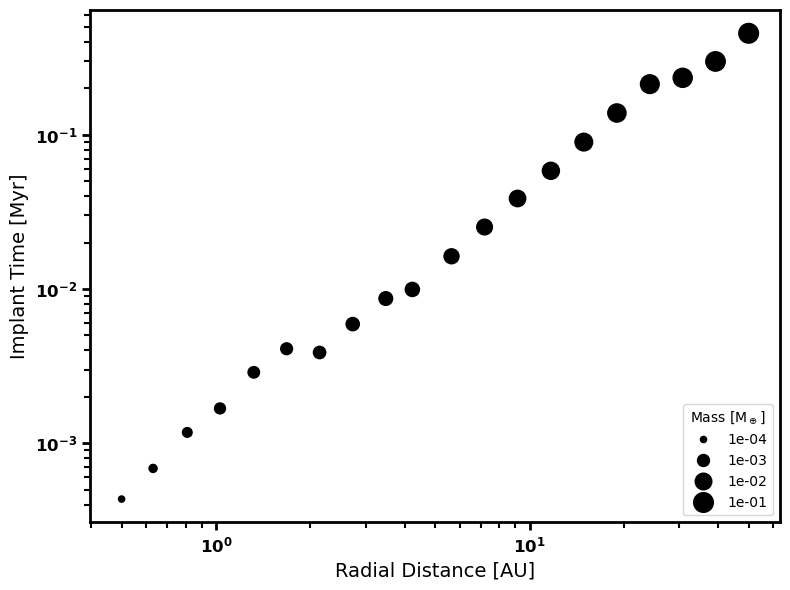

In [19]:
if "SI" in config["planets"]["Mp"]:
    fig, ax = plt.subplots(figsize = (8, 6))

    ## Mass and radius at formation (first non-NaN value in Mp / Rp for each planet)

    n_planets = len(Mp)
    M0 = np.full(n_planets, np.nan)
    R0 = np.full(n_planets, np.nan)

    for i in range(n_planets):
        valid = ~np.isnan(Mp[i])

        if np.any(valid):
            M0[i] = Mp[i][valid][0]

        valid_R = ~np.isnan(Rp[i])

        if np.any(valid_R):
            R0[i] = Rp[i][valid_R][0]

    ## Map mass to marker size on a log scale

    s_min, s_max = 20, 200
    logM0 = np.log10(M0)
    logM0_min, logM0_max = np.nanmin(logM0), np.nanmax(logM0)
    s = s_min + (logM0 - logM0_min) / (logM0_max - logM0_min) * (s_max - s_min)

    ax.scatter(R0, t_form / 1e6, s = s, color = 'black')

    ax.set_xscale('log')
    ax.set_yscale('log')
    ax.set_xlabel('Radial Distance [AU]')
    ax.set_ylabel('Implant Time [Myr]')

    ## Size legend, one marker per order of magnitude spanned by the data

    mag_min = int(np.floor(logM0_min))
    mag_max = int(np.ceil(logM0_max))
    mass_ticks = 10.0 ** np.arange(mag_min, mag_max + 1)
    size_ticks = s_min + (np.log10(mass_ticks) - logM0_min) / (logM0_max - logM0_min) * (s_max - s_min)
    size_ticks = np.clip(size_ticks, s_min, s_max)

    size_handles = [
        Line2D([0], [0], marker = 'o', linestyle = 'None', color = 'black', markersize = np.sqrt(sz), label = f'{mt:.0e}')
        for mt, sz in zip(mass_ticks, size_ticks)]

    ax.legend(handles = size_handles, title = r'Mass [M$_\oplus$]', loc = 'lower right', fontsize = 10)

    bold_ticks(ax)

    plt.tight_layout()

    if save_figures:
        figure_path = os.path.join(figure_dir, f"planet_implant_times.png")
        plt.savefig(figure_path)

    plt.show()